In [1]:
# ============================================================================
# STEP 1: INSTALL AND IMPORT LIBRARIES
# ============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2
import shutil
from pathlib import Path
import kagglehub
import json
import random

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras import mixed_precision

# Metrics
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split

# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("="*70)
print("PLANT DISEASE DETECTION - SETUP COMPLETE")
print("="*70)
print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {len(tf.config.list_physical_devices('GPU')) > 0}")
print(f"GPU Devices: {tf.config.list_physical_devices('GPU')}")
gpus = tf.config.list_physical_devices('GPU') 
if gpus: 
    for gpu in gpus: 
        tf.config.experimental.set_memory_growth(gpu, True) 
    print("✅ GPU memory growth enabled") # Enable mixed precision (if GPU supports Tensor Cores) 
mixed_precision.set_global_policy('mixed_float16') 
print("✅ Mixed precision enabled") 
# Enable XLA compiler 
tf.config.optimizer.set_jit(True) 
print("✅ XLA compiler enabled")
TF_CPP_MIN_LOG_LEVEL='3'
TF_ENABLE_ONEDNN_OPTS='0'
tf.get_logger().setLevel('ERROR') 
tf.autograph.set_verbosity(0) 

2026-01-15 22:25:55.590403: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-15 22:25:56.179857: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-01-15 22:25:58.361561: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


PLANT DISEASE DETECTION - SETUP COMPLETE
TensorFlow Version: 2.20.0
GPU Available: True
GPU Devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ GPU memory growth enabled
✅ Mixed precision enabled
✅ XLA compiler enabled


In [2]:
# ============================================================================
# STEP 2: DOWNLOAD DATASET USING KAGGLEHUB 
# ============================================================================

print("\n" + "="*70)
print("STEP 2: DOWNLOADING DATASET USING KAGGLEHUB")
print("="*70)

# Download dataset
dataset_path = "/mnt/c/Users/Jimmy/anaconda_projects/cv project/plantvillage dataset" 
print("✓ Local dataset path set successfully!") 
print("Path to dataset files:", dataset_path)


STEP 2: DOWNLOADING DATASET USING KAGGLEHUB
✓ Local dataset path set successfully!
Path to dataset files: /mnt/c/Users/Jimmy/anaconda_projects/cv project/plantvillage dataset



STEP 3: DEFINING CLASSES
Classes defined: 10
  1. healthy
  2. Early blight
  3. Late blight
  4. Bacterial spot
  5. Leaf Mold
  6. Septoria leaf spot
  7. Spider mites Two-spotted spider mite
  8. Target Spot
  9. Tomato mosaic virus
  10. Tomato Yellow Leaf Curl Virus

STEP 3A: ORIGINAL DATASET ANALYSIS (BEFORE DOWNSAMPLING)

ANALYZE ORIGINAL DATASET BEFORE DOWNSAMPLING

Analyze dataset from: /mnt/c/Users/Jimmy/anaconda_projects/cv project/plantvillage dataset/segmented
Classes to analyze: 10

Class Name                                    Image Count    
healthy                                            1,591
Early blight                                       1,000
Late blight                                        1,909
Bacterial spot                                     2,127
Leaf Mold                                            952
Septoria leaf spot                                 1,771
Spider mites Two-spotted spider mite               1,676
Target Spot                         

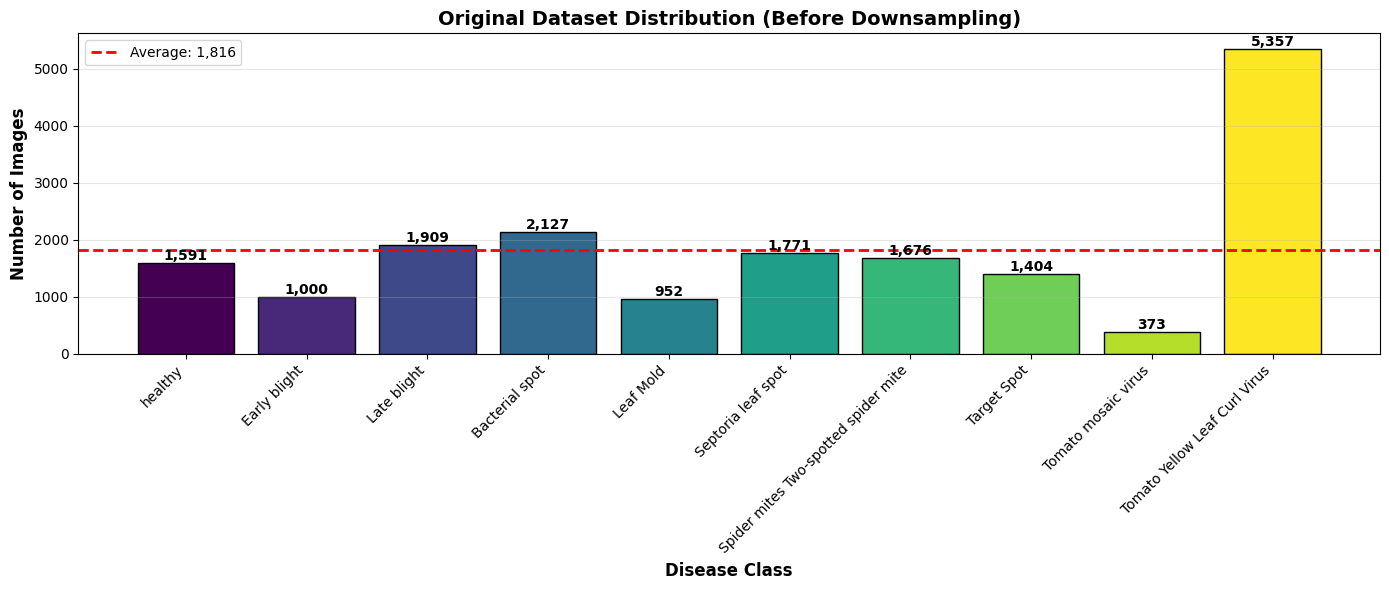


COMPARISON: BEFORE vs AFTER DOWNSAMPLING (target=1000)
Class                                    Original        After Downsample     Reduction      
healthy                                       1,591          1,000            37.1%
Early blight                                  1,000          1,000             0.0%
Late blight                                   1,909          1,000            47.6%
Bacterial spot                                2,127          1,000            53.0%
Leaf Mold                                       952            952             0.0%
Septoria leaf spot                            1,771          1,000            43.5%
Spider mites Two-spotted spider mite          1,676          1,000            40.3%
Target Spot                                   1,404          1,000            28.8%
Tomato mosaic virus                             373            373             0.0%
Tomato Yellow Leaf Curl Virus                 5,357          1,000            81.3%


In [3]:
# ============================================================================
# STEP 3: DEFINE CLASSES
# ============================================================================

print("\n" + "="*70)
print("STEP 3: DEFINING CLASSES")
print("="*70)

# Define the classes for Tomato Disease Detection
CLASSES = [
    'Tomato___healthy',
    'Tomato___Early_blight', 
    'Tomato___Late_blight',
    'Tomato___Bacterial_spot',
    'Tomato___Leaf_Mold',
    'Tomato___Septoria_leaf_spot',
    'Tomato___Spider_mites Two-spotted_spider_mite',
    'Tomato___Target_Spot',
    'Tomato___Tomato_mosaic_virus',
    'Tomato___Tomato_Yellow_Leaf_Curl_Virus',
]

print(f"Classes defined: {len(CLASSES)}")
for i, cls in enumerate(CLASSES, 1):
    display_name = cls.replace('Tomato___', '').replace('_', ' ')
    print(f"  {i}. {display_name}")

# ============================================================================
# STEP 3A: ANALYZE ORIGINAL DATASET BEFORE DOWNSAMPLING
# ============================================================================

print("\n" + "="*70)
print("STEP 3A: ORIGINAL DATASET ANALYSIS (BEFORE DOWNSAMPLING)")
print("="*70)

def analyze_original_dataset(source_dir, classes_to_use):
    """
    Analyze the original dataset to see class distribution before downsampling
    
    Args:
        source_dir: Path to dataset (segmented folder)
        classes_to_use: List of class folder names to analyze
    """
    
    print(f"\nAnalyze dataset from: {source_dir}")
    print(f"Classes to analyze: {len(classes_to_use)}\n")
    
    class_counts = {}
    
    # Count images in each class
    print("="*70)
    print(f"{'Class Name':<45} {'Image Count':<15}")
    print("="*70)
    
    for class_name in classes_to_use:
        source_class_dir = os.path.join(source_dir, class_name)
        
        if not os.path.exists(source_class_dir):
            print(f"{class_name:<45} NOT FOUND")
            class_counts[class_name] = 0
            continue
        
        # Count images
        images = [f for f in os.listdir(source_class_dir) 
                 if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        
        count = len(images)
        class_counts[class_name] = count
        
        # Clean name for display
        display_name = class_name.replace('Tomato___', '').replace('_', ' ')
        print(f"{display_name:<45} {count:>10,}")
    
    # Calculate statistics
    total_images = sum(class_counts.values())
    max_count = max(class_counts.values())
    min_count = min(class_counts.values())
    avg_count = total_images / len(classes_to_use) if classes_to_use else 0
    
    print("="*70)
    print(f"\n{'DATASET STATISTICS'}")
    print("="*70)
    print(f"Total Images:        {total_images:>10,}")
    print(f"Number of Classes:   {len(classes_to_use):>10,}")
    print(f"Average per Class:   {avg_count:>10,.0f}")
    print(f"Maximum Count:       {max_count:>10,}")
    print(f"Minimum Count:       {min_count:>10,}")
    print(f"Imbalance Ratio:     {max_count/min_count if min_count > 0 else 0:>10.2f}:1")
    
    # Visualize distribution
    plt.figure(figsize=(14, 6))
    
    # Clean class names for plotting
    clean_names = [name.replace('Tomato___', '').replace('_', ' ') for name in classes_to_use]
    counts = [class_counts[name] for name in classes_to_use]
    
    # Create bar plot
    colors = plt.cm.viridis(np.linspace(0, 1, len(classes_to_use)))
    bars = plt.bar(range(len(classes_to_use)), counts, color=colors, edgecolor='black')
    
    plt.xlabel('Disease Class', fontsize=12, fontweight='bold')
    plt.ylabel('Number of Images', fontsize=12, fontweight='bold')
    plt.title('Original Dataset Distribution (Before Downsampling)', fontsize=14, fontweight='bold')
    plt.xticks(range(len(classes_to_use)), clean_names, rotation=45, ha='right')
    plt.grid(axis='y', alpha=0.3)
    
    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height,
                f'{int(height):,}',
                ha='center', va='bottom', fontweight='bold')
    
    # Add horizontal line for average
    plt.axhline(y=avg_count, color='red', linestyle='--', linewidth=2, 
                label=f'Average: {avg_count:,.0f}')
    plt.legend()
    
    plt.tight_layout()
    plt.show()
    
    return class_counts

# Analyze original dataset
print("\n" + "="*70)
print("ANALYZE ORIGINAL DATASET BEFORE DOWNSAMPLING")
print("="*70)
SOURCE_DIR = os.path.join(dataset_path, "segmented")
original_counts = analyze_original_dataset(SOURCE_DIR, CLASSES)

# Show what will happen after downsampling
print("\n" + "="*70)
print("COMPARISON: BEFORE vs AFTER DOWNSAMPLING (target=1000)")
print("="*70)
print(f"{'Class':<40} {'Original':<15} {'After Downsample':<20} {'Reduction':<15}")
print("="*70)

target_count = 1000
for class_name in CLASSES:
    original = original_counts.get(class_name, 0)
    after = min(original, target_count)
    reduction = ((original - after) / original * 100) if original > 0 else 0
    
    clean_name = class_name.replace('Tomato___', '').replace('_', ' ')
    print(f"{clean_name:<40} {original:>10,}     {after:>10,}          {reduction:>6.1f}%")

print("="*70)

In [14]:
# # ============================================================================
# # STEP 3B: ORGANIZE DATASET INTO TRAIN/VAL/TEST SPLITS
# # ============================================================================

def organize_dataset_downsample(source_dir, output_dir, classes_to_use, target_count=700,train_ratio=0.7, val_ratio=0.15, test_ratio=0.15):
    """
    Downsample each class to target_count images and split into train/val/test.
    
    Args:
        source_dir: Path to dataset (segmented folder)
        output_dir: Where to save organized dataset
        classes_to_use: List of class folder names to use
        target_count: Number of images per class after downsampling
        train_ratio: Proportion for training (default 0.7)
        val_ratio: Proportion for validation (default 0.15)
        test_ratio: Proportion for testing (default 0.15)
    """
    print("\n" + "="*70)
    print("STEP 3B: ORIGINAL DATASET ANALYSIS (AFTER DOWNSAMPLING)")
    print("="*70)
    # Create output directories
    splits = ['train', 'validation', 'test']
    for split in splits:
        for class_name in classes_to_use:
            Path(os.path.join(output_dir, split, class_name)).mkdir(parents=True, exist_ok=True)
    
    print(f"\nOrganize dataset from: {source_dir}")
    print(f"Output directory: {output_dir}")
    print(f"Classes: {classes_to_use}")
    print(f"Target count per class: {target_count}")
    print(f"Split ratio - Train: {train_ratio}, Val: {val_ratio}, Test: {test_ratio}\n")
    
    # Process each class
    for class_name in classes_to_use:
        source_class_dir = os.path.join(source_dir, class_name)
        
        if not os.path.exists(source_class_dir):
            print(f"Warning: {source_class_dir} not found! Skipping...")
            continue
        
        # Get all images
        images = [f for f in os.listdir(source_class_dir) 
                 if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        
        # Shuffle images
        random.shuffle(images)
        
        # Downsample to target_count (or fewer if not enough images)
        selected = images[:target_count]
        total = len(selected)
        
        # Calculate split indices
        train_end = int(total * train_ratio)
        val_end = train_end + int(total * val_ratio)
        
        # Split images
        train_images = selected[:train_end]
        val_images = selected[train_end:val_end]
        test_images = selected[val_end:]
        
        # Copy files
        for split, split_images in [('train', train_images), 
                                     ('validation', val_images), 
                                     ('test', test_images)]:
            dest_dir = os.path.join(output_dir, split, class_name)
            
            for img in split_images:
                src = os.path.join(source_class_dir, img)
                dst = os.path.join(dest_dir, img)
                shutil.copy2(src, dst)
        
        print(f"{class_name:40s} - Train: {len(train_images):4d}, Val: {len(val_images):4d}, Test: {len(test_images):4d}, Total: {total:4d}")
    
    print("\n✓ Dataset organization with downsampling complete!")
    return output_dir

# Example usage:
SOURCE_DIR = os.path.join(dataset_path, "segmented")
OUTPUT_DIR = 'dataset'
CLASSES = [
    'Tomato___healthy',
    'Tomato___Early_blight', 
    'Tomato___Late_blight',
    'Tomato___Septoria_leaf_spot',
    'Tomato___Tomato_Yellow_Leaf_Curl_Virus',
]

organize_dataset_downsample(SOURCE_DIR, OUTPUT_DIR, CLASSES, target_count=1000)



STEP 3B: ORIGINAL DATASET ANALYSIS (AFTER DOWNSAMPLING)

Organize dataset from: /mnt/c/Users/Jimmy/anaconda_projects/cv project/plantvillage dataset/segmented
Output directory: dataset
Classes: ['Tomato___healthy', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Septoria_leaf_spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus']
Target count per class: 1000
Split ratio - Train: 0.7, Val: 0.15, Test: 0.15

Tomato___healthy                         - Train:  700, Val:  150, Test:  150, Total: 1000
Tomato___Early_blight                    - Train:  700, Val:  150, Test:  150, Total: 1000
Tomato___Late_blight                     - Train:  700, Val:  150, Test:  150, Total: 1000
Tomato___Septoria_leaf_spot              - Train:  700, Val:  150, Test:  150, Total: 1000
Tomato___Tomato_Yellow_Leaf_Curl_Virus   - Train:  700, Val:  150, Test:  150, Total: 1000

✓ Dataset organization with downsampling complete!


'dataset'


STEP 4: DATASET EXPLORATION

DATASET STATISTICS

Training Set:
  Tomato___Early_blight                   :   700 images ( 20.0%)
  Tomato___Late_blight                    :   700 images ( 20.0%)
  Tomato___Septoria_leaf_spot             :   700 images ( 20.0%)
  Tomato___Tomato_Yellow_Leaf_Curl_Virus  :   700 images ( 20.0%)
  Tomato___healthy                        :   700 images ( 20.0%)
  Total                                   :  3500 images

Validation Set:
  Tomato___Early_blight                   :   150 images ( 20.0%)
  Tomato___Late_blight                    :   150 images ( 20.0%)
  Tomato___Septoria_leaf_spot             :   150 images ( 20.0%)
  Tomato___Tomato_Yellow_Leaf_Curl_Virus  :   150 images ( 20.0%)
  Tomato___healthy                        :   150 images ( 20.0%)
  Total                                   :   750 images

Test Set:
  Tomato___Early_blight                   :   150 images ( 20.0%)
  Tomato___Late_blight                    :   150 images ( 20.0%)
  

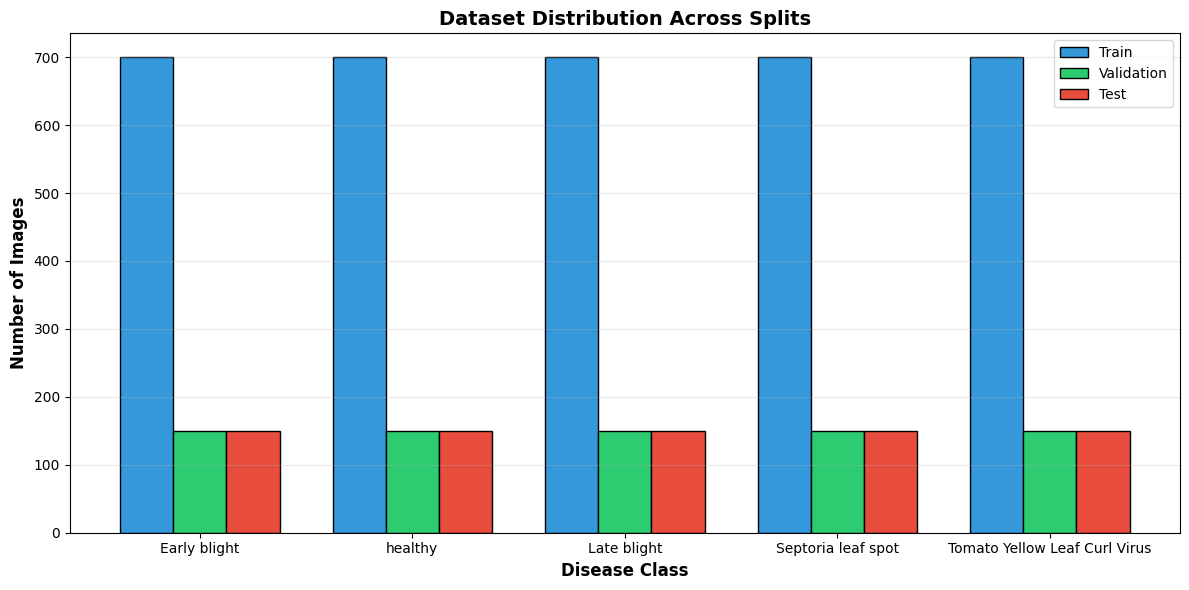

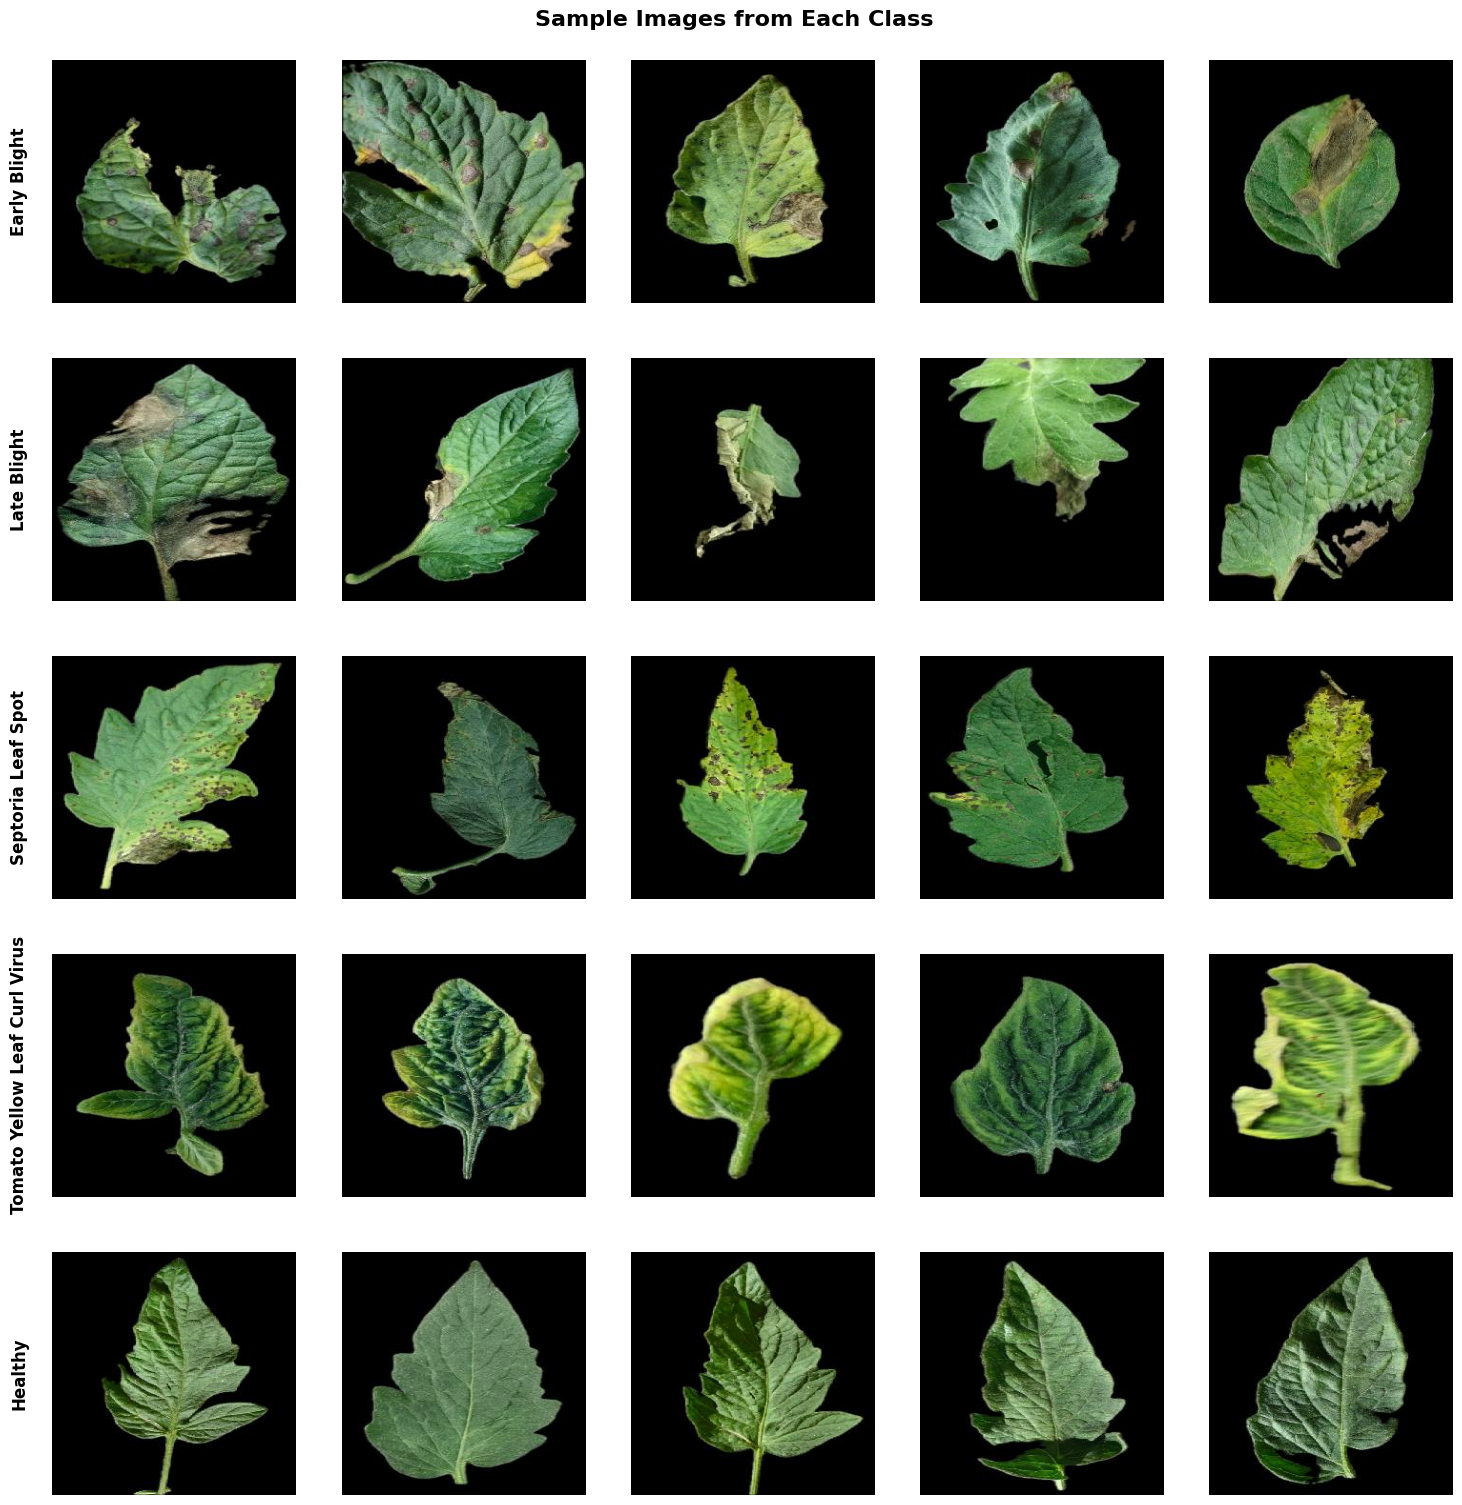

In [4]:
# ============================================================================
# STEP 4: VERIFY DATASET AND EXPLORE
# ============================================================================

print("\n" + "="*70)
print("STEP 4: DATASET EXPLORATION")
print("="*70)

# Set paths
BASE_DIR = 'dataset'
TRAIN_DIR = os.path.join(BASE_DIR, 'train')
VAL_DIR = os.path.join(BASE_DIR, 'validation')
TEST_DIR = os.path.join(BASE_DIR, 'test')

# Image parameters
IMG_SIZE = 224
BATCH_SIZE = 48  # Increased for better GPU utilization
NUM_CLASSES = 5
CLASS_NAMES=['Tomato___healthy', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Septoria_leaf_spot',  'Tomato___Tomato_Yellow_Leaf_Curl_Virus']
def count_images(directory):
    """Count images in each class"""
    if not os.path.exists(directory):
        print(f"Directory {directory} does not exist!")
        return {}
    
    class_counts = {}
    for class_name in os.listdir(directory):
        class_path = os.path.join(directory, class_name)
        if os.path.isdir(class_path):
            count = len([f for f in os.listdir(class_path) 
                        if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
            class_counts[class_name] = count
    return class_counts

def display_dataset_info():
    """Display comprehensive dataset information"""
    print("\n" + "="*70)
    print("DATASET STATISTICS")
    print("="*70)
    
    for split_name, split_dir in [('Training', TRAIN_DIR), 
                                   ('Validation', VAL_DIR), 
                                   ('Test', TEST_DIR)]:
        counts = count_images(split_dir)
        if counts:
            total = sum(counts.values())
            print(f"\n{split_name} Set:")
            for class_name, count in sorted(counts.items()):
                percentage = (count / total * 100) if total > 0 else 0
                print(f"  {class_name:40s}: {count:5d} images ({percentage:5.1f}%)")
            print(f"  {'Total':40s}: {total:5d} images")
    
    # Check for class imbalance
    train_counts = count_images(TRAIN_DIR)
    if train_counts:
        max_count = max(train_counts.values())
        min_count = min(train_counts.values())
        imbalance_ratio = max_count / min_count if min_count > 0 else 0
        
        print(f"\n{'='*70}")
        print(f"Class Imbalance Ratio: {imbalance_ratio:.2f}:1")
        if imbalance_ratio > 3:
            print("⚠️  Warning: Significant class imbalance detected!")
        else:
            print("✓ Dataset is reasonably balanced")

# Run dataset info 
display_dataset_info()

def plot_class_distribution():
    """Visualize class distribution across splits"""
    splits = ['train', 'validation', 'test']
    data = []
    
    for split in splits:
        split_dir = os.path.join(BASE_DIR, split)
        counts = count_images(split_dir)
        for class_name, count in counts.items():
            # Clean class name for display
            clean_name = class_name.replace('Tomato___', '').replace('_', ' ')
            data.append({'Split': split.capitalize(), 'Class': clean_name, 'Count': count})
    
    df = pd.DataFrame(data)
    
    # Create grouped bar chart
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Get unique classes and splits
    classes = df['Class'].unique()
    x = np.arange(len(classes))
    width = 0.25
    
    colors = ['#3498db', '#2ecc71', '#e74c3c']
    
    for i, split in enumerate(['Train', 'Validation', 'Test']):
        split_data = df[df['Split'] == split]
        counts = [split_data[split_data['Class'] == c]['Count'].values[0] 
                 if len(split_data[split_data['Class'] == c]) > 0 else 0 
                 for c in classes]
        ax.bar(x + i*width, counts, width, label=split, color=colors[i], edgecolor='black')
    
    ax.set_xlabel('Disease Class', fontsize=12, fontweight='bold')
    ax.set_ylabel('Number of Images', fontsize=12, fontweight='bold')
    ax.set_title('Dataset Distribution Across Splits', fontsize=14, fontweight='bold')
    ax.set_xticks(x + width)
    ax.set_xticklabels(classes, rotation=0)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# Plot distribution 
plot_class_distribution()

def show_sample_images():
    """Display sample images from each class"""
    if not os.path.exists(TRAIN_DIR):
        print("Training directory not found!")
        return
    
    classes = sorted([d for d in os.listdir(TRAIN_DIR) 
                     if os.path.isdir(os.path.join(TRAIN_DIR, d))])
    
    fig, axes = plt.subplots(len(classes), 5, figsize=(15, 3*len(classes)))
    fig.suptitle('Sample Images from Each Class', fontsize=16, fontweight='bold', y=1.00)
    
    for i, class_name in enumerate(classes):
        class_dir = os.path.join(TRAIN_DIR, class_name)
        images = [f for f in os.listdir(class_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        
        # Clean name for display
        clean_name = class_name.replace('Tomato___', '').replace('_', ' ').title()
        
        for j in range(5):
            if j < len(images):
                img_path = os.path.join(class_dir, images[j])
                img = Image.open(img_path)
                
                if len(classes) > 1:
                    ax = axes[i, j]
                else:
                    ax = axes[j]
                
                ax.imshow(img)
                ax.axis('off')
                
                if j == 0:
                    ax.text(-0.1, 0.5, clean_name, transform=ax.transAxes,
                           fontsize=12, fontweight='bold', va='center', ha='right',
                           rotation=90)
    
    plt.tight_layout()
    plt.show()

# Show samples 
show_sample_images()



STEP 5: DATA PREPROCESSING & AUGMENTATION

Creating data generators...
Found 3500 images belonging to 5 classes.
Found 750 images belonging to 5 classes.
Found 750 images belonging to 5 classes.

✓ Data generators created successfully!
  Training samples: 3500
  Validation samples: 750
  Test samples: 750
  Training steps per epoch: 73
  Validation steps per epoch: 16
  Class indices: {'Tomato___Early_blight': 0, 'Tomato___Late_blight': 1, 'Tomato___Septoria_leaf_spot': 2, 'Tomato___Tomato_Yellow_Leaf_Curl_Virus': 3, 'Tomato___healthy': 4}
Found 3500 images belonging to 5 classes.
Found 3500 images belonging to 5 classes.


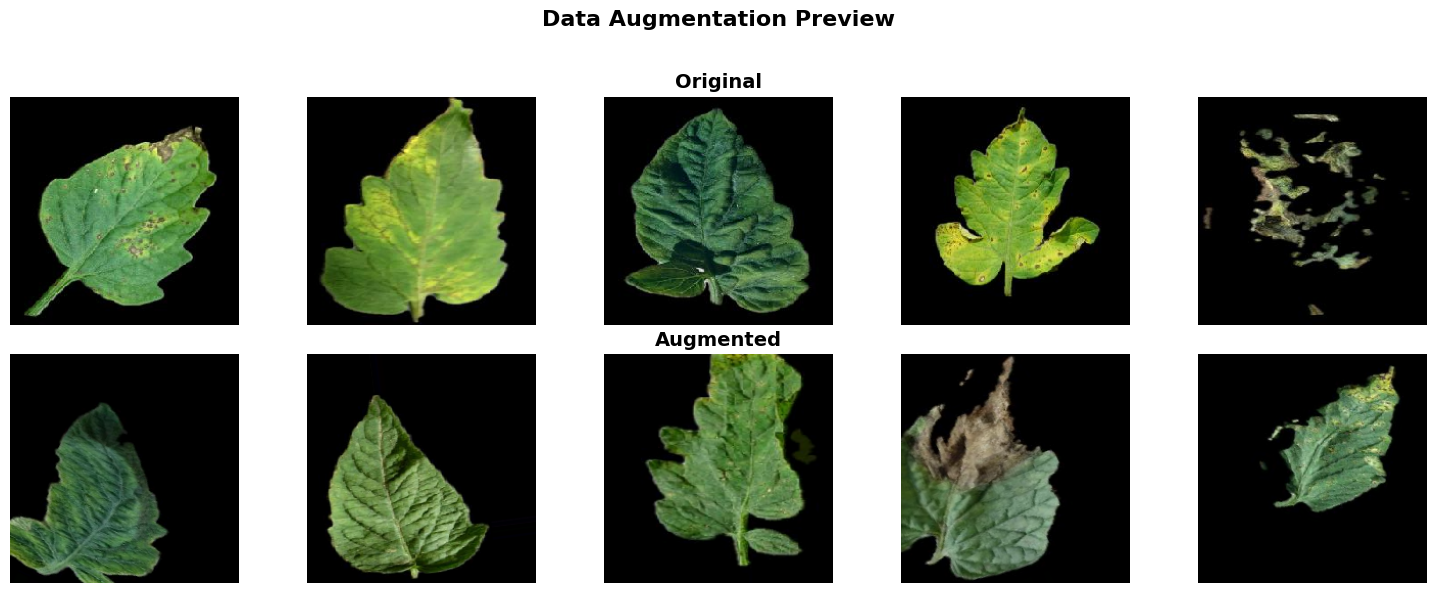

In [3]:
# ============================================================================
# STEP 5: DATA PREPROCESSING AND AUGMENTATION
# ============================================================================

print("\n" + "="*70)
print("STEP 5: DATA PREPROCESSING & AUGMENTATION")
print("="*70)

# Training data augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=False,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

# Validation and test (only rescaling)
val_test_datagen = ImageDataGenerator(rescale=1./255)

def create_generators():
    """Create data generators for train, validation, and test sets"""
    
    print("\nCreating data generators...")
    
    # Training generator
    train_generator = train_datagen.flow_from_directory(
        TRAIN_DIR,
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        shuffle=True,
        seed=42
    )
    
    # Validation generator
    val_generator = val_test_datagen.flow_from_directory(
        VAL_DIR,
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        shuffle=False
    )
    
    # Test generator
    test_generator = val_test_datagen.flow_from_directory(
        TEST_DIR,
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        shuffle=False
    )
    
    print(f"\n✓ Data generators created successfully!")
    print(f"  Training samples: {train_generator.samples}")
    print(f"  Validation samples: {val_generator.samples}")
    print(f"  Test samples: {test_generator.samples}")
    print(f"  Training steps per epoch: {len(train_generator)}")
    print(f"  Validation steps per epoch: {len(val_generator)}")
    print(f"  Class indices: {train_generator.class_indices}")
    
    # Return generators directly (not converted to Dataset)
    # This preserves step count information
    return train_generator, val_generator, test_generator

# Create generators 
train_gen, val_gen, test_gen = create_generators()

def visualize_augmentation(train_dir, datagen, num_images=5):
    """Visualize original vs augmented images with clear row labels"""

    # Generator without augmentation (only rescaling)
    plain_datagen = ImageDataGenerator(rescale=1./255)
    plain_gen = plain_datagen.flow_from_directory(
        train_dir,
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=num_images,
        class_mode='categorical',
        shuffle=True
    )

    # Generator with augmentation
    aug_gen = datagen.flow_from_directory(
        train_dir,
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=num_images,
        class_mode='categorical',
        shuffle=True
    )

    # Fetch one batch from each
    plain_images, _ = next(plain_gen)
    aug_images, _ = next(aug_gen)

    fig, axes = plt.subplots(2, num_images, figsize=(15, 6))
    fig.suptitle('Data Augmentation Preview', fontsize=16, fontweight='bold')

    # Top row: original images
    for i in range(num_images):
        axes[0, i].imshow(plain_images[i])
        axes[0, i].axis('off')
    # Add a row label as a title spanning the row
    axes[0, num_images//2].set_title('Original', fontsize=14, fontweight='bold')

    # Bottom row: augmented images
    for i in range(num_images):
        axes[1, i].imshow(aug_images[i])
        axes[1, i].axis('off')
    axes[1, num_images//2].set_title('Augmented', fontsize=14, fontweight='bold')

    plt.tight_layout(rect=[0, 0, 1, 0.95])  # leave space for the main title
    plt.show()



# Visualize augmentation (uncomment after creating generators)
visualize_augmentation(TRAIN_DIR, train_datagen, num_images=5)



In [4]:
# ============================================================================
# STEP 6: BUILD CUSTOM CNN MODEL
# ============================================================================

print("\n" + "="*70)
print("STEP 6: BUILDING CUSTOM CNN")
print("="*70)

def build_custom_cnn():
    """Build custom CNN from scratch"""
    
    model = models.Sequential(name='Custom_CNN')
    
    # Input layer
    model.add(layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)))
    
    # Block 1
    model.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.25))
    
    # Block 2
    model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.25))
    
    # Block 3
    model.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.25))
    
    # Block 4
    model.add(layers.Conv2D(256, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.25))
    
    # Fully connected layers
    model.add(layers.Flatten())
    model.add(layers.Dense(512, activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.5))
    
    model.add(layers.Dense(256, activation='relu'))
    model.add(layers.Dropout(0.5))
    
    # Output layer
    model.add(layers.Dense(NUM_CLASSES, activation='softmax'))
    
    return model

# Build custom CNN
custom_cnn = build_custom_cnn()

# Compile model
custom_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy', 
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')]
)

print("\n✓ Custom CNN built successfully!")
print("\nModel Architecture:")
custom_cnn.summary()

print(f"\nTotal Parameters: {custom_cnn.count_params():,}")
trainable_params = sum([tf.size(w).numpy() for w in custom_cnn.trainable_weights])
print(f"Trainable Parameters: {trainable_params:,}")


STEP 6: BUILDING CUSTOM CNN


I0000 00:00:1768222913.973771     844 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3537 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9



✓ Custom CNN built successfully!

Model Architecture:


Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 26,410,277 (100.75 MB)

 Trainable params: 26,407,845 (100.74 MB)

 Non-trainable params: 2,432 (9.50 KB)


Total Parameters: 26,410,277
Trainable Parameters: 26,407,845


In [5]:
# ============================================================================
# STEP 7: BUILD TRANSFER LEARNING MODEL (MobileNetV2)
# ============================================================================

print("\n" + "="*70)
print("STEP 7: BUILDING TRANSFER LEARNING MODEL (MobileNetV2)")
print("="*70)


def build_transfer_learning_model():
    """Build transfer learning model using MobileNetV2"""
    
    # Load pre-trained base model
    base_model = MobileNetV2(
        include_top=False,          # exclude original ImageNet classifier
        weights='imagenet',         # use pre-trained ImageNet weights
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    
    # Freeze base model
    base_model.trainable = False
    
    # Build complete model
    model = models.Sequential(name='Transfer_Learning_MobileNetV2')
    model.add(base_model)
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.5))
    
    model.add(layers.Dense(256, activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.3))
    
    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dropout(0.3))
    
    model.add(layers.Dense(NUM_CLASSES, activation='softmax'))
    
    return model, base_model

# Build transfer learning model
mobilenet_model, base_model = build_transfer_learning_model()

# Compile model
mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy',
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')]
)

print("\n✓ Transfer Learning model (MobileNetV2) built successfully!")
print("\nModel Architecture:")
mobilenet_model.summary()

print(f"\nBase Model Layers: {len(base_model.layers)}")
print(f"Base Model Trainable: {base_model.trainable}")
print(f"Total Parameters: {mobilenet_model.count_params():,}")
trainable_params = sum([tf.size(w).numpy() for w in mobilenet_model.trainable_weights])
print(f"Trainable Parameters: {trainable_params:,}")



STEP 7: BUILDING TRANSFER LEARNING MODEL (MobileNetV2)

✓ Transfer Learning model (MobileNetV2) built successfully!

Model Architecture:


Model: "Transfer_Learning_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,625,605 (10.02 MB)

 Trainable params: 364,549 (1.39 MB)

 Non-trainable params: 2,261,056 (8.63 MB)


Base Model Layers: 154
Base Model Trainable: False
Total Parameters: 2,625,605
Trainable Parameters: 364,549


In [6]:
# ============================================================================
# STEP 8: TRAIN CUSTOM CNN
# ============================================================================

print("\n" + "="*70)
print("STEP 8: TRAINING CUSTOM CNN")
print("="*70)

# Create models directory
os.makedirs('models', exist_ok=True)

# Callbacks
custom_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=14,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=10,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        'models/custom_cnn_best.h5',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

EPOCHS = 60

print(f"\nTraining Configuration:")
print(f"  Epochs: {EPOCHS}")
print(f"  Batch Size: {BATCH_SIZE}")
print(f"  Image Size: {IMG_SIZE}x{IMG_SIZE}")
print(f"  Optimizer: Adam (lr=0.001)")
print(f"  Loss: Categorical Crossentropy")

# Train custom CNN 
print("\n" + "="*70)
print("STARTING TRAINING - CUSTOM CNN")
print("="*70)

history_custom = custom_cnn.fit(
    train_gen,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=custom_callbacks,
    verbose=1
)

#Save final model
custom_cnn.save('models/custom_cnn_final.keras')
print("\n✓ Custom CNN training complete!")
print("  Model saved to: models/custom_cnn_final.keras")


STEP 8: TRAINING CUSTOM CNN

Training Configuration:
  Epochs: 60
  Batch Size: 48
  Image Size: 224x224
  Optimizer: Adam (lr=0.001)
  Loss: Categorical Crossentropy

STARTING TRAINING - CUSTOM CNN
Epoch 1/60


2026-01-12 21:02:04.175580: I external/local_xla/xla/service/service.cc:163] XLA service 0x716414003be0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-01-12 21:02:04.175615: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9
2026-01-12 21:02:04.203040: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002
I0000 00:00:1768222924.402294    1420 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
2026-01-12 21:02:08.809680: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-01-12 21:02:10.510887: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Ma

12/73 ━━━━━━━━━━━━━━━━━━━━ 1:33 2s/step - accuracy: 0.1941 - loss: 2.9955 - precision: 0.2013 - recall: 0.1534

2026-01-12 21:03:15.861393: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-01-12 21:03:15.861461: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-01-12 21:03:23.551088: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng0{} for conv (f16[44,112,112,64]{3,2,1,0}, u8[0]{0}) custom-call(f16[44,112,112,64]{3,2,1,0}, f16[64,3,3,64]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=b01f_o01i->b01f, custom_call_target="__cudnn$convBackwardInput", backend_config={"operati

73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3021 - loss: 2.3272 - precision: 0.3259 - recall: 0.2107
Epoch 1: val_accuracy improved from None to 0.20000, saving model to models/custom_cnn_best.h5


...

73/73 ━━━━━━━━━━━━━━━━━━━━ 63s 864ms/step - accuracy: 0.9280 - loss: 0.1961 - precision: 0.9357 - recall: 0.9234 - val_accuracy: 0.8627 - val_loss: 0.5309 - val_precision: 0.8711 - val_recall: 0.8560 - learning_rate: 5.0000e-04
Epoch 29/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 662ms/step - accuracy: 0.9353 - loss: 0.1842 - precision: 0.9408 - recall: 0.9294
Epoch 29: val_accuracy did not improve from 0.86267
73/73 ━━━━━━━━━━━━━━━━━━━━ 55s 754ms/step - accuracy: 0.9303 - loss: 0.1908 - precision: 0.9363 - recall: 0.9234 - val_accuracy: 0.7347 - val_loss: 1.3178 - val_precision: 0.7411 - val_recall: 0.7253 - learning_rate: 5.0000e-04
Epoch 30/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 693ms/step - accuracy: 0.9315 - loss: 0.1874 - precision: 0.9406 - recall: 0.9255
Epoch 30: val_accuracy did not improve from 0.86267
73/73 ━━━━━━━━━━━━━━━━━━━━ 57s 787ms/step - accuracy: 0.9337 - loss: 0.1907 - precision: 0.9404 - recall: 0.9283 - val_accuracy: 0.7240 - val_loss: 1.5812 - val_precision: 0.7268 - val_recall:

73/73 ━━━━━━━━━━━━━━━━━━━━ 62s 843ms/step - accuracy: 0.9511 - loss: 0.1397 - precision: 0.9540 - recall: 0.9474 - val_accuracy: 0.8773 - val_loss: 0.4741 - val_precision: 0.8820 - val_recall: 0.8773 - learning_rate: 5.0000e-04
Epoch 43/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 709ms/step - accuracy: 0.9465 - loss: 0.1723 - precision: 0.9495 - recall: 0.9414
Epoch 43: val_accuracy did not improve from 0.87733
73/73 ━━━━━━━━━━━━━━━━━━━━ 59s 804ms/step - accuracy: 0.9494 - loss: 0.1541 - precision: 0.9533 - recall: 0.9451 - val_accuracy: 0.7573 - val_loss: 0.9154 - val_precision: 0.7734 - val_recall: 0.7507 - learning_rate: 5.0000e-04
Epoch 44/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 714ms/step - accuracy: 0.9429 - loss: 0.1512 - precision: 0.9465 - recall: 0.9377
Epoch 44: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 44: val_accuracy did not improve from 0.87733
73/73 ━━━━━━━━━━━━━━━━━━━━ 59s 812ms/step - accuracy: 0.9451 - loss: 0.1522 - precision: 0.9482 - recall: 0.9406 -

73/73 ━━━━━━━━━━━━━━━━━━━━ 63s 862ms/step - accuracy: 0.9566 - loss: 0.1317 - precision: 0.9588 - recall: 0.9520 - val_accuracy: 0.8787 - val_loss: 0.3884 - val_precision: 0.8807 - val_recall: 0.8760 - learning_rate: 2.5000e-04
Epoch 46/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 690ms/step - accuracy: 0.9567 - loss: 0.1195 - precision: 0.9588 - recall: 0.9535
Epoch 46: val_accuracy did not improve from 0.87867
73/73 ━━━━━━━━━━━━━━━━━━━━ 59s 806ms/step - accuracy: 0.9603 - loss: 0.1213 - precision: 0.9623 - recall: 0.9563 - val_accuracy: 0.8787 - val_loss: 0.4141 - val_precision: 0.8862 - val_recall: 0.8720 - learning_rate: 2.5000e-04
Epoch 47/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 654ms/step - accuracy: 0.9646 - loss: 0.1014 - precision: 0.9669 - recall: 0.9630
Epoch 47: val_accuracy improved from 0.87867 to 0.90000, saving model to models/custom_cnn_best.h5


73/73 ━━━━━━━━━━━━━━━━━━━━ 58s 793ms/step - accuracy: 0.9637 - loss: 0.1036 - precision: 0.9656 - recall: 0.9620 - val_accuracy: 0.9000 - val_loss: 0.3814 - val_precision: 0.9047 - val_recall: 0.8987 - learning_rate: 2.5000e-04
Epoch 48/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 668ms/step - accuracy: 0.9548 - loss: 0.1411 - precision: 0.9580 - recall: 0.9513
Epoch 48: val_accuracy did not improve from 0.90000
73/73 ━━━━━━━━━━━━━━━━━━━━ 56s 755ms/step - accuracy: 0.9571 - loss: 0.1267 - precision: 0.9608 - recall: 0.9534 - val_accuracy: 0.8707 - val_loss: 0.5103 - val_precision: 0.8808 - val_recall: 0.8667 - learning_rate: 2.5000e-04
Epoch 49/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 659ms/step - accuracy: 0.9567 - loss: 0.1017 - precision: 0.9602 - recall: 0.9551
Epoch 49: val_accuracy did not improve from 0.90000
73/73 ━━━━━━━━━━━━━━━━━━━━ 56s 769ms/step - accuracy: 0.9580 - loss: 0.1068 - precision: 0.9601 - recall: 0.9554 - val_accuracy: 0.8333 - val_loss: 0.7301 - val_precision: 0.8383 - val_recall:

73/73 ━━━━━━━━━━━━━━━━━━━━ 57s 773ms/step - accuracy: 0.9671 - loss: 0.0933 - precision: 0.9695 - recall: 0.9643 - val_accuracy: 0.9173 - val_loss: 0.2960 - val_precision: 0.9197 - val_recall: 0.9160 - learning_rate: 2.5000e-04
Epoch 51/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 656ms/step - accuracy: 0.9546 - loss: 0.1141 - precision: 0.9568 - recall: 0.9531
Epoch 51: val_accuracy did not improve from 0.91733
73/73 ━━━━━━━━━━━━━━━━━━━━ 55s 744ms/step - accuracy: 0.9617 - loss: 0.1035 - precision: 0.9644 - recall: 0.9606 - val_accuracy: 0.8613 - val_loss: 0.5865 - val_precision: 0.8658 - val_recall: 0.8600 - learning_rate: 2.5000e-04
Epoch 52/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 729ms/step - accuracy: 0.9649 - loss: 0.0978 - precision: 0.9690 - recall: 0.9639
Epoch 52: val_accuracy did not improve from 0.91733
73/73 ━━━━━━━━━━━━━━━━━━━━ 61s 833ms/step - accuracy: 0.9643 - loss: 0.0965 - precision: 0.9681 - recall: 0.9623 - val_accuracy: 0.8707 - val_loss: 0.4106 - val_precision: 0.8769 - val_recall:

In [7]:
# ============================================================================
# STEP 9: TRAIN TRANSFER LEARNING MODEL (MobileNetV2) - Phase 1 Only
# ============================================================================

print("\n" + "="*70)
print("STEP 9: TRAINING TRANSFER LEARNING MODEL (MobileNetV2) - Phase 1 Only")
print("="*70)

transfer_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=14,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=10,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        'models/transfer_learning_mobilenetv2_best.h5',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

# -------------------------------
# PHASE 1: Training with frozen base model
# -------------------------------
print("\n" + "="*70)
print("PHASE 1: Training with frozen MobileNetV2 base model")
print("="*70)

# Ensure base model is frozen
base_model.trainable = False

history_mobilenet_phase1 = mobilenet_model.fit(
    train_gen,
    epochs=60,
    validation_data=val_gen,
    callbacks=transfer_callbacks,
    verbose=1
)

# Save final model after Phase 1
mobilenet_model.save('models/transfer_learning_mobilenetv2_final.keras')
print("\n✓ Transfer Learning training with MobileNetV2 (Phase 1 only) complete!")
print("  Model saved to: models/transfer_learning_mobilenetv2_final.keras")


STEP 9: TRAINING TRANSFER LEARNING MODEL (MobileNetV2) - Phase 1 Only

PHASE 1: Training with frozen MobileNetV2 base model
Epoch 1/60


2026-01-12 22:03:20.715810: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-01-12 22:03:20.716345: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-01-12 22:03:20.716367: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-01-12 22:03:21.261541: I external/l

47/73 ━━━━━━━━━━━━━━━━━━━━ 16s 643ms/step - accuracy: 0.4202 - loss: 1.5880 - precision: 0.4867 - recall: 0.3557

2026-01-12 22:04:01.559304: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-01-12 22:04:01.559403: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-01-12 22:04:01.559416: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-01-12 22:04:02.285305: I external/l

73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 784ms/step - accuracy: 0.4913 - loss: 1.4026 - precision: 0.5573 - recall: 0.4319

...

73/73 ━━━━━━━━━━━━━━━━━━━━ 54s 739ms/step - accuracy: 0.8926 - loss: 0.2842 - precision: 0.9053 - recall: 0.8823 - val_accuracy: 0.9307 - val_loss: 0.1906 - val_precision: 0.9391 - val_recall: 0.9253 - learning_rate: 0.0010
Epoch 24/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 618ms/step - accuracy: 0.9036 - loss: 0.2558 - precision: 0.9121 - recall: 0.8901
Epoch 24: val_accuracy improved from 0.93067 to 0.93467, saving model to models/transfer_learning_mobilenetv2_best.h5


73/73 ━━━━━━━━━━━━━━━━━━━━ 54s 734ms/step - accuracy: 0.9020 - loss: 0.2647 - precision: 0.9123 - recall: 0.8886 - val_accuracy: 0.9347 - val_loss: 0.1837 - val_precision: 0.9429 - val_recall: 0.9240 - learning_rate: 0.0010
Epoch 25/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 618ms/step - accuracy: 0.9038 - loss: 0.2421 - precision: 0.9196 - recall: 0.8952
Epoch 25: val_accuracy did not improve from 0.93467
73/73 ━━━━━━━━━━━━━━━━━━━━ 51s 700ms/step - accuracy: 0.9011 - loss: 0.2568 - precision: 0.9167 - recall: 0.8926 - val_accuracy: 0.9280 - val_loss: 0.1940 - val_precision: 0.9387 - val_recall: 0.9187 - learning_rate: 0.0010
Epoch 26/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 645ms/step - accuracy: 0.9122 - loss: 0.2591 - precision: 0.9184 - recall: 0.9013
Epoch 26: val_accuracy did not improve from 0.93467
73/73 ━━━━━━━━━━━━━━━━━━━━ 53s 731ms/step - accuracy: 0.9060 - loss: 0.2638 - precision: 0.9136 - recall: 0.8946 - val_accuracy: 0.9267 - val_loss: 0.1883 - val_precision: 0.9336 - val_recall: 0.9187 

73/73 ━━━━━━━━━━━━━━━━━━━━ 56s 769ms/step - accuracy: 0.9034 - loss: 0.2600 - precision: 0.9141 - recall: 0.8911 - val_accuracy: 0.9373 - val_loss: 0.1711 - val_precision: 0.9482 - val_recall: 0.9267 - learning_rate: 0.0010
Epoch 38/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 666ms/step - accuracy: 0.9124 - loss: 0.2200 - precision: 0.9227 - recall: 0.9003
Epoch 38: val_accuracy did not improve from 0.93733
73/73 ━━━━━━━━━━━━━━━━━━━━ 56s 772ms/step - accuracy: 0.9091 - loss: 0.2389 - precision: 0.9167 - recall: 0.8994 - val_accuracy: 0.9333 - val_loss: 0.1781 - val_precision: 0.9454 - val_recall: 0.9227 - learning_rate: 0.0010
Epoch 39/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 664ms/step - accuracy: 0.8981 - loss: 0.2538 - precision: 0.9133 - recall: 0.8913
Epoch 39: val_accuracy did not improve from 0.93733
73/73 ━━━━━━━━━━━━━━━━━━━━ 55s 753ms/step - accuracy: 0.9043 - loss: 0.2398 - precision: 0.9171 - recall: 0.8971 - val_accuracy: 0.9267 - val_loss: 0.1897 - val_precision: 0.9372 - val_recall: 0.9160 

73/73 ━━━━━━━━━━━━━━━━━━━━ 54s 740ms/step - accuracy: 0.9080 - loss: 0.2359 - precision: 0.9166 - recall: 0.9009 - val_accuracy: 0.9400 - val_loss: 0.1618 - val_precision: 0.9458 - val_recall: 0.9307 - learning_rate: 0.0010
Epoch 42/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 628ms/step - accuracy: 0.9039 - loss: 0.2498 - precision: 0.9150 - recall: 0.8910
Epoch 42: val_accuracy did not improve from 0.94000
73/73 ━━━━━━━━━━━━━━━━━━━━ 52s 713ms/step - accuracy: 0.9020 - loss: 0.2565 - precision: 0.9126 - recall: 0.8917 - val_accuracy: 0.9333 - val_loss: 0.1706 - val_precision: 0.9432 - val_recall: 0.9293 - learning_rate: 0.0010
Epoch 43/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 631ms/step - accuracy: 0.9123 - loss: 0.2396 - precision: 0.9221 - recall: 0.9049
Epoch 43: val_accuracy did not improve from 0.94000
73/73 ━━━━━━━━━━━━━━━━━━━━ 53s 732ms/step - accuracy: 0.9137 - loss: 0.2379 - precision: 0.9235 - recall: 0.9031 - val_accuracy: 0.9360 - val_loss: 0.1739 - val_precision: 0.9444 - val_recall: 0.9293 

73/73 ━━━━━━━━━━━━━━━━━━━━ 55s 750ms/step - accuracy: 0.9126 - loss: 0.2359 - precision: 0.9198 - recall: 0.9049 - val_accuracy: 0.9453 - val_loss: 0.1578 - val_precision: 0.9514 - val_recall: 0.9387 - learning_rate: 0.0010
Epoch 49/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 641ms/step - accuracy: 0.9134 - loss: 0.2265 - precision: 0.9256 - recall: 0.9025
Epoch 49: val_accuracy did not improve from 0.94533
73/73 ━━━━━━━━━━━━━━━━━━━━ 53s 725ms/step - accuracy: 0.9129 - loss: 0.2314 - precision: 0.9245 - recall: 0.9026 - val_accuracy: 0.9413 - val_loss: 0.1710 - val_precision: 0.9486 - val_recall: 0.9347 - learning_rate: 0.0010
Epoch 50/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 662ms/step - accuracy: 0.9240 - loss: 0.2099 - precision: 0.9338 - recall: 0.9177
Epoch 50: val_accuracy did not improve from 0.94533
73/73 ━━━━━━━━━━━━━━━━━━━━ 55s 751ms/step - accuracy: 0.9163 - loss: 0.2225 - precision: 0.9263 - recall: 0.9080 - val_accuracy: 0.9240 - val_loss: 0.1828 - val_precision: 0.9398 - val_recall: 0.9160 

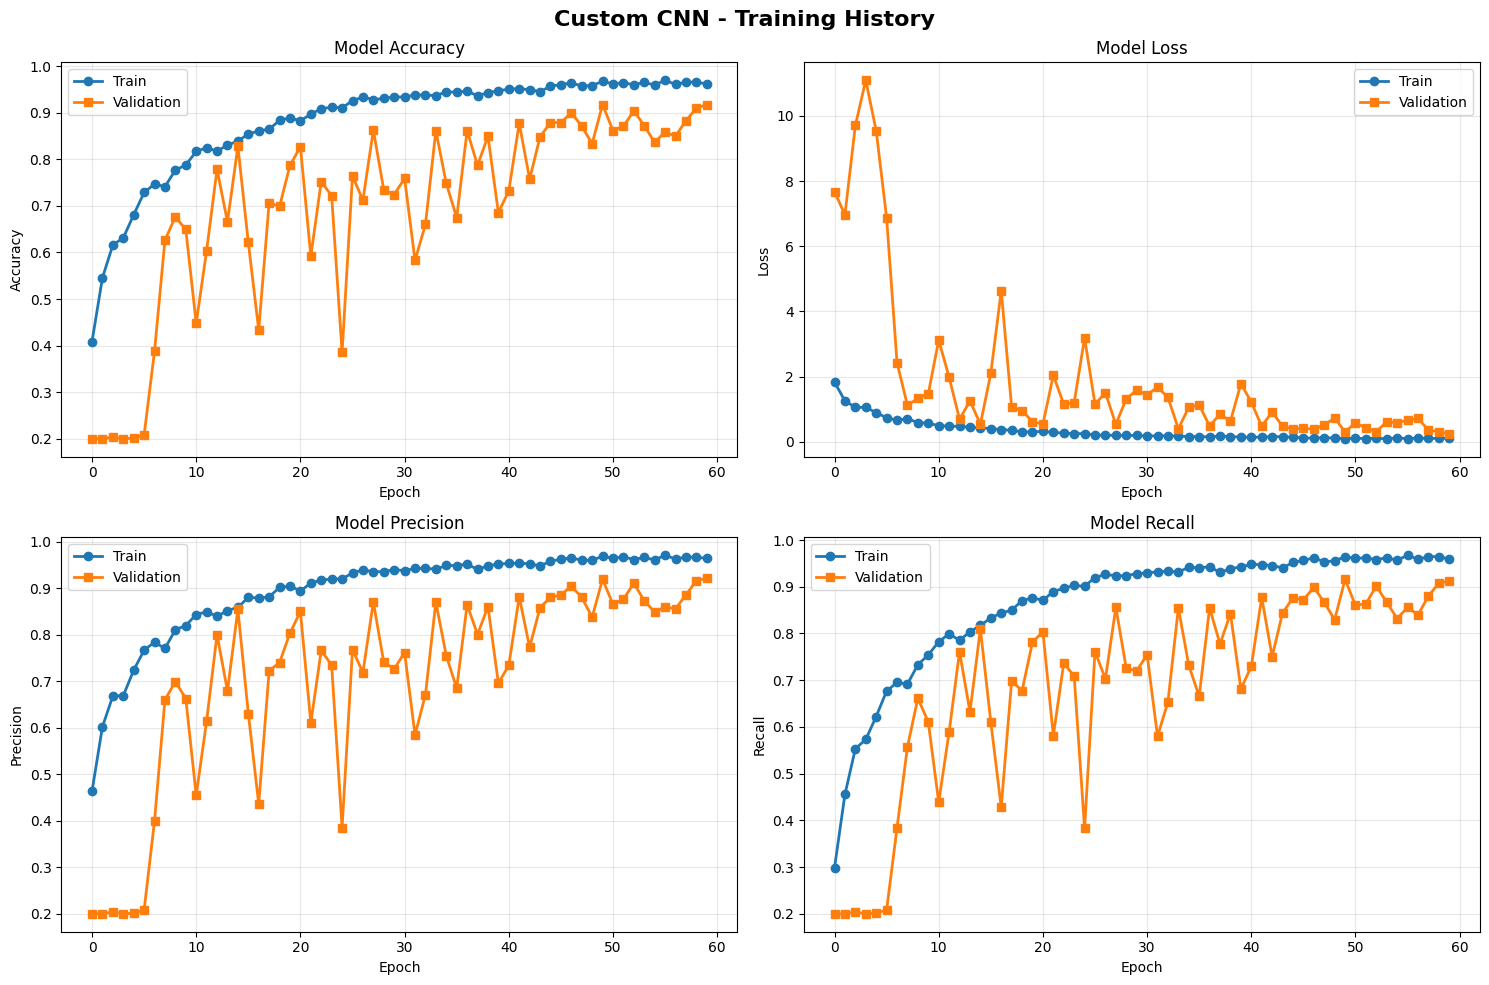

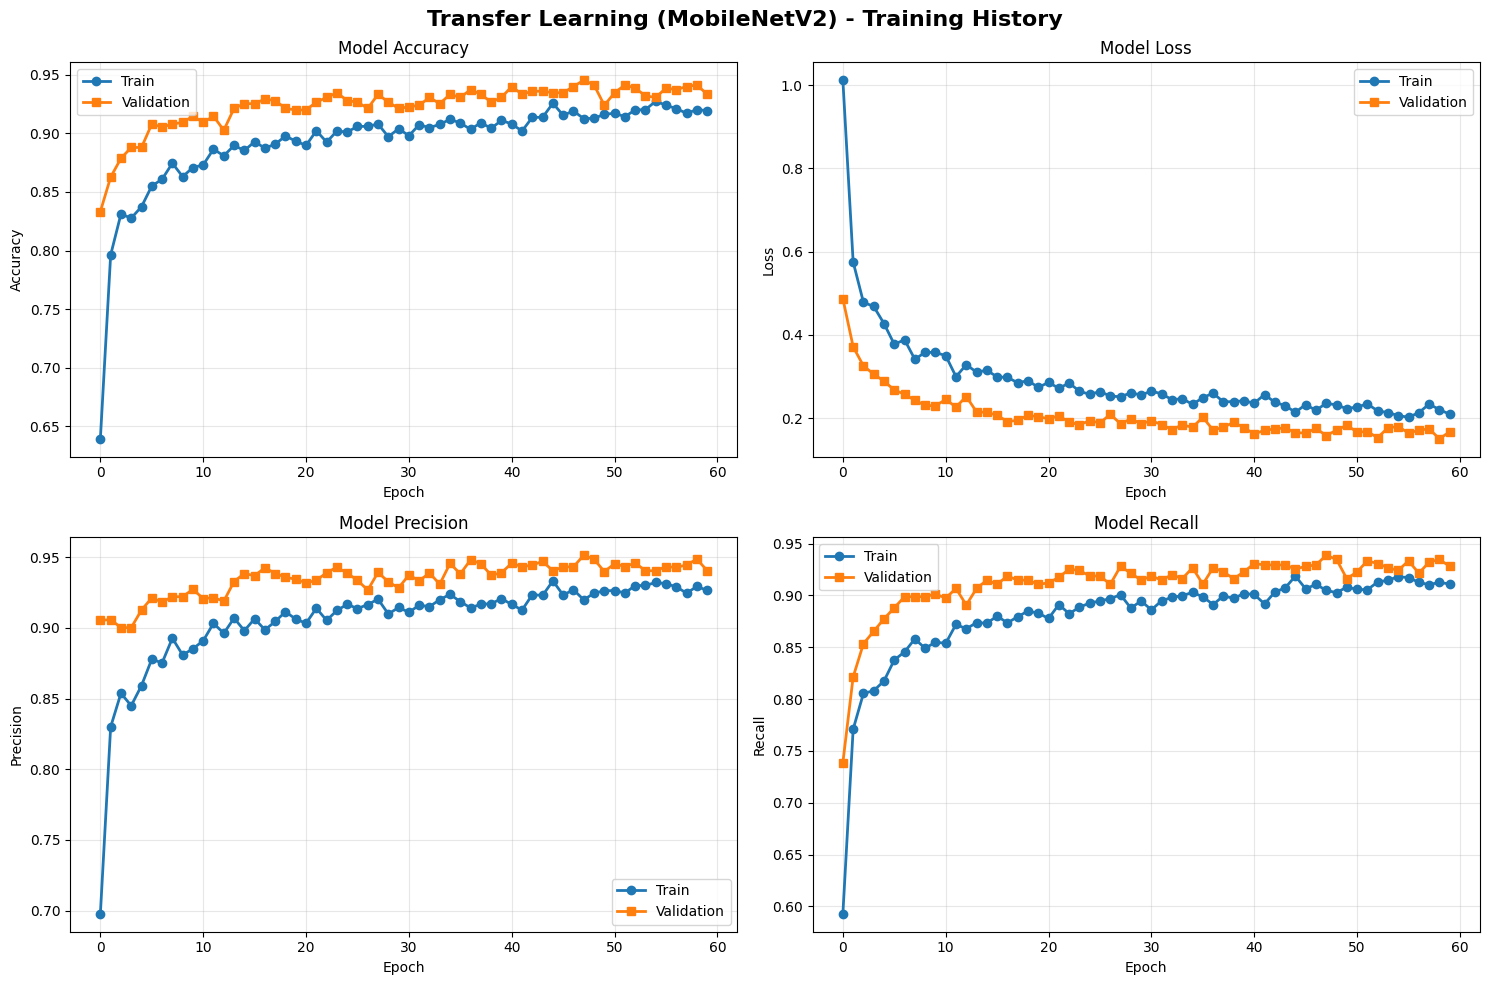

In [15]:
# ============================================================================
# STEP 10: VISUALIZE TRAINING HISTORY
# ============================================================================

def plot_training_history(history, model_name='Model'):
    """Plot training curves"""
    
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle(f'{model_name} - Training History', fontsize=16, fontweight='bold')
    
    # Accuracy
    axes[0, 0].plot(history.history['accuracy'], label='Train', linewidth=2, marker='o')
    axes[0, 0].plot(history.history['val_accuracy'], label='Validation', linewidth=2, marker='s')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Accuracy')
    axes[0, 0].set_title('Model Accuracy')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # Loss
    axes[0, 1].plot(history.history['loss'], label='Train', linewidth=2, marker='o')
    axes[0, 1].plot(history.history['val_loss'], label='Validation', linewidth=2, marker='s')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Loss')
    axes[0, 1].set_title('Model Loss')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # Precision
    if 'precision' in history.history:
        axes[1, 0].plot(history.history['precision'], label='Train', linewidth=2, marker='o')
        axes[1, 0].plot(history.history['val_precision'], label='Validation', linewidth=2, marker='s')
        axes[1, 0].set_xlabel('Epoch')
        axes[1, 0].set_ylabel('Precision')
        axes[1, 0].set_title('Model Precision')
        axes[1, 0].legend()
        axes[1, 0].grid(True, alpha=0.3)
    
    # Recall
    if 'recall' in history.history:
        axes[1, 1].plot(history.history['recall'], label='Train', linewidth=2, marker='o')
        axes[1, 1].plot(history.history['val_recall'], label='Validation', linewidth=2, marker='s')
        axes[1, 1].set_xlabel('Epoch')
        axes[1, 1].set_ylabel('Recall')
        axes[1, 1].set_title('Model Recall')
        axes[1, 1].legend()
        axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# ============================================================================
# Plot histories for all models
# ============================================================================

# Custom CNN
plot_training_history(history_custom, 'Custom CNN')

# MobileNetV2 Transfer Learning
plot_training_history(history_mobilenet_phase1, 'Transfer Learning (MobileNetV2)')


STEP 11: MODEL EVALUATION

EVALUATING: Custom CNN

Generating predictions...


2026-01-12 22:57:23.596173: E tensorflow/core/util/util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


16/16 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step

OVERALL ACCURACY: 89.20%

Detailed Classification Report:
                               precision    recall  f1-score   support

                 Early blight     0.9703    0.6533    0.7809       150
                  Late blight     0.8333    0.9000    0.8654       150
           Septoria leaf spot     0.8111    0.9733    0.8848       150
Tomato Yellow Leaf Curl Virus     1.0000    0.9400    0.9691       150
                      healthy     0.8976    0.9933    0.9430       150

                     accuracy                         0.8920       750
                    macro avg     0.9025    0.8920    0.8886       750
                 weighted avg     0.9025    0.8920    0.8886       750



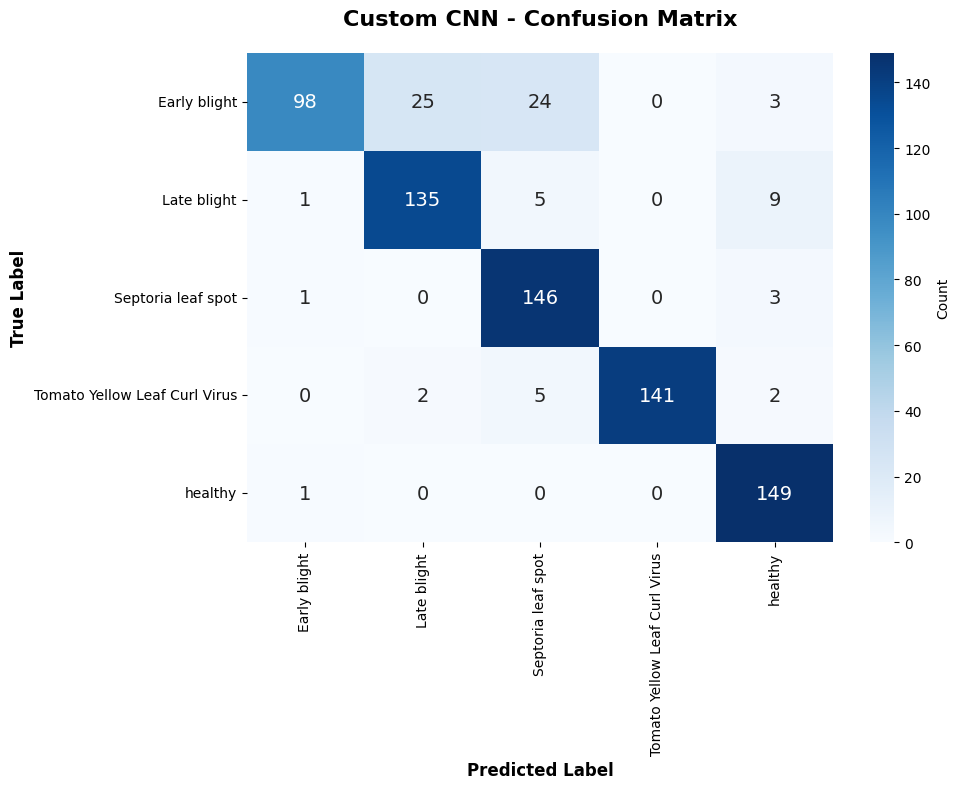


Per-Class Performance:
Class                          Accuracy     Precision    Recall       F1-Score    
Early blight                    65.33%      0.9703       0.6533       0.7809
Late blight                     90.00%      0.8333       0.9000       0.8654
Septoria leaf spot              97.33%      0.8111       0.9733       0.8848
Tomato Yellow Leaf Curl Virus   94.00%      1.0000       0.9400       0.9691
healthy                         99.33%      0.8976       0.9933       0.9430

EVALUATING: Transfer Learning - MobileNetV2

Generating predictions...
16/16 ━━━━━━━━━━━━━━━━━━━━ 12s 530ms/step

OVERALL ACCURACY: 94.53%

Detailed Classification Report:
                               precision    recall  f1-score   support

                 Early blight     0.9143    0.8533    0.8828       150
                  Late blight     0.9211    0.9333    0.9272       150
           Septoria leaf spot     0.9236    0.9667    0.9446       150
Tomato Yellow Leaf Curl Virus     0.9932    0.9800

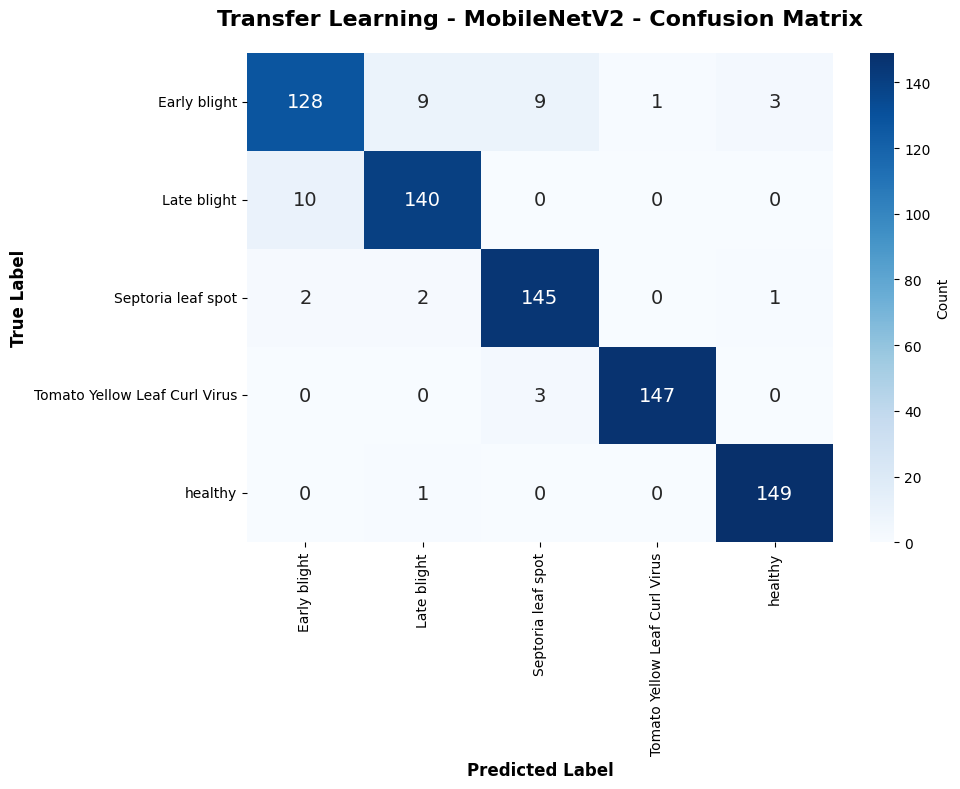


Per-Class Performance:
Class                          Accuracy     Precision    Recall       F1-Score    
Early blight                    85.33%      0.9143       0.8533       0.8828
Late blight                     93.33%      0.9211       0.9333       0.9272
Septoria leaf spot              96.67%      0.9236       0.9667       0.9446
Tomato Yellow Leaf Curl Virus   98.00%      0.9932       0.9800       0.9866
healthy                         99.33%      0.9739       0.9933       0.9835

MODEL COMPARISON SUMMARY
Model                                    Accuracy        Parameters     
Custom CNN                                89.20%          26,410,277
Transfer Learning (MobileNetV2)           94.53%           2,625,605

✓ Best performing model: MobileNetV2 with accuracy 94.53%


In [10]:
# ============================================================================
# STEP 11: EVALUATE MODELS
# ============================================================================

print("\n" + "="*70)
print("STEP 11: MODEL EVALUATION")
print("="*70)

def evaluate_model(model, test_generator, model_name='Model'):
    """Comprehensive model evaluation"""
    
    print(f"\n{'='*70}")
    print(f"EVALUATING: {model_name}")
    print(f"{'='*70}")
    
    # Reset generator
    test_generator.reset()
    
    # Get predictions
    print("\nGenerating predictions...")
    predictions = model.predict(test_generator, verbose=1)
    y_pred = np.argmax(predictions, axis=1)
    y_true = test_generator.classes
    
    # Get class names
    class_names = list(test_generator.class_indices.keys())
    class_names = [name.replace('Tomato___', '').replace('_', ' ') for name in class_names]
    
    # Calculate metrics
    accuracy = accuracy_score(y_true, y_pred)
    
    print(f"\n{'='*70}")
    print(f"OVERALL ACCURACY: {accuracy*100:.2f}%")
    print(f"{'='*70}")
    
    # Classification report
    print("\nDetailed Classification Report:")
    print("="*70)
    report = classification_report(y_true, y_pred, target_names=class_names, digits=4)
    print(report)
    
    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    
    # Plot confusion matrix
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                cbar_kws={'label': 'Count'}, annot_kws={'size': 14})
    plt.title(f'{model_name} - Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
    plt.ylabel('True Label', fontsize=12, fontweight='bold')
    plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Per-class metrics
    print("\nPer-Class Performance:")
    print("="*70)
    print(f"{'Class':<30} {'Accuracy':<12} {'Precision':<12} {'Recall':<12} {'F1-Score':<12}")
    print("="*70)
    
    for i, class_name in enumerate(class_names):
        class_acc = cm[i, i] / cm[i].sum() * 100 if cm[i].sum() > 0 else 0
        
        # Calculate precision, recall, f1
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
        
        print(f"{class_name:<30} {class_acc:>6.2f}%      {precision:>6.4f}       {recall:>6.4f}       {f1:>6.4f}")
    
    return y_pred, y_true, accuracy, predictions


# ============================================================================
# Evaluate models (uncomment after training)
# ============================================================================

# Evaluate Custom CNN
custom_pred, custom_true, custom_acc, custom_predictions = evaluate_model(
    custom_cnn, test_gen, 'Custom CNN'
)

# Evaluate Transfer Learning - MobileNetV2
mobilenet_pred, mobilenet_true, mobilenet_acc, mobilenet_predictions = evaluate_model( mobilenet_model, test_gen, 'Transfer Learning - MobileNetV2'
)

# ============================================================================
# Compare models
# ============================================================================

print("\n" + "="*70)
print("MODEL COMPARISON SUMMARY")
print("="*70)
print(f"{'Model':<40} {'Accuracy':<15} {'Parameters':<15}")
print("="*70)
print(f"{'Custom CNN':<40} {custom_acc*100:>6.2f}%        {custom_cnn.count_params():>12,}")
print(f"{'Transfer Learning (MobileNetV2)':<40} {mobilenet_acc*100:>6.2f}%        {mobilenet_model.count_params():>12,}")
print("="*70)


# Highlight best performer
best_model = max(
    [('Custom CNN', custom_acc),
     ('MobileNetV2', mobilenet_acc)],
    key=lambda x: x[1]
)

print(f"\n✓ Best performing model: {best_model[0]} with accuracy {best_model[1]*100:.2f}%")


2026-01-12 22:57:59.904260: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng10{k2=8,k13=1,k14=4,k18=1,k23=0} for conv (f16[32,224,224,32]{3,2,1,0}, u8[0]{0}) custom-call(f16[32,224,224,3]{3,2,1,0}, f16[32,3,3,3]{3,2,1,0}, f16[32]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=b01f_o01i->b01f, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kRelu","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-01-12 22:57:59.935890: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.551262954s
Trying algorithm eng10{k2=8,k13=1,k14=4,k18=1,k23=0} for conv (f16[32,224,224,32]{3,2,1,0}, u8[0]{0}) custom-call(f16[32,224,224,3]{3,2,1,0}, f16[32,3,3,3]{3,2,1,0}, f16[32]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=b01f_o01

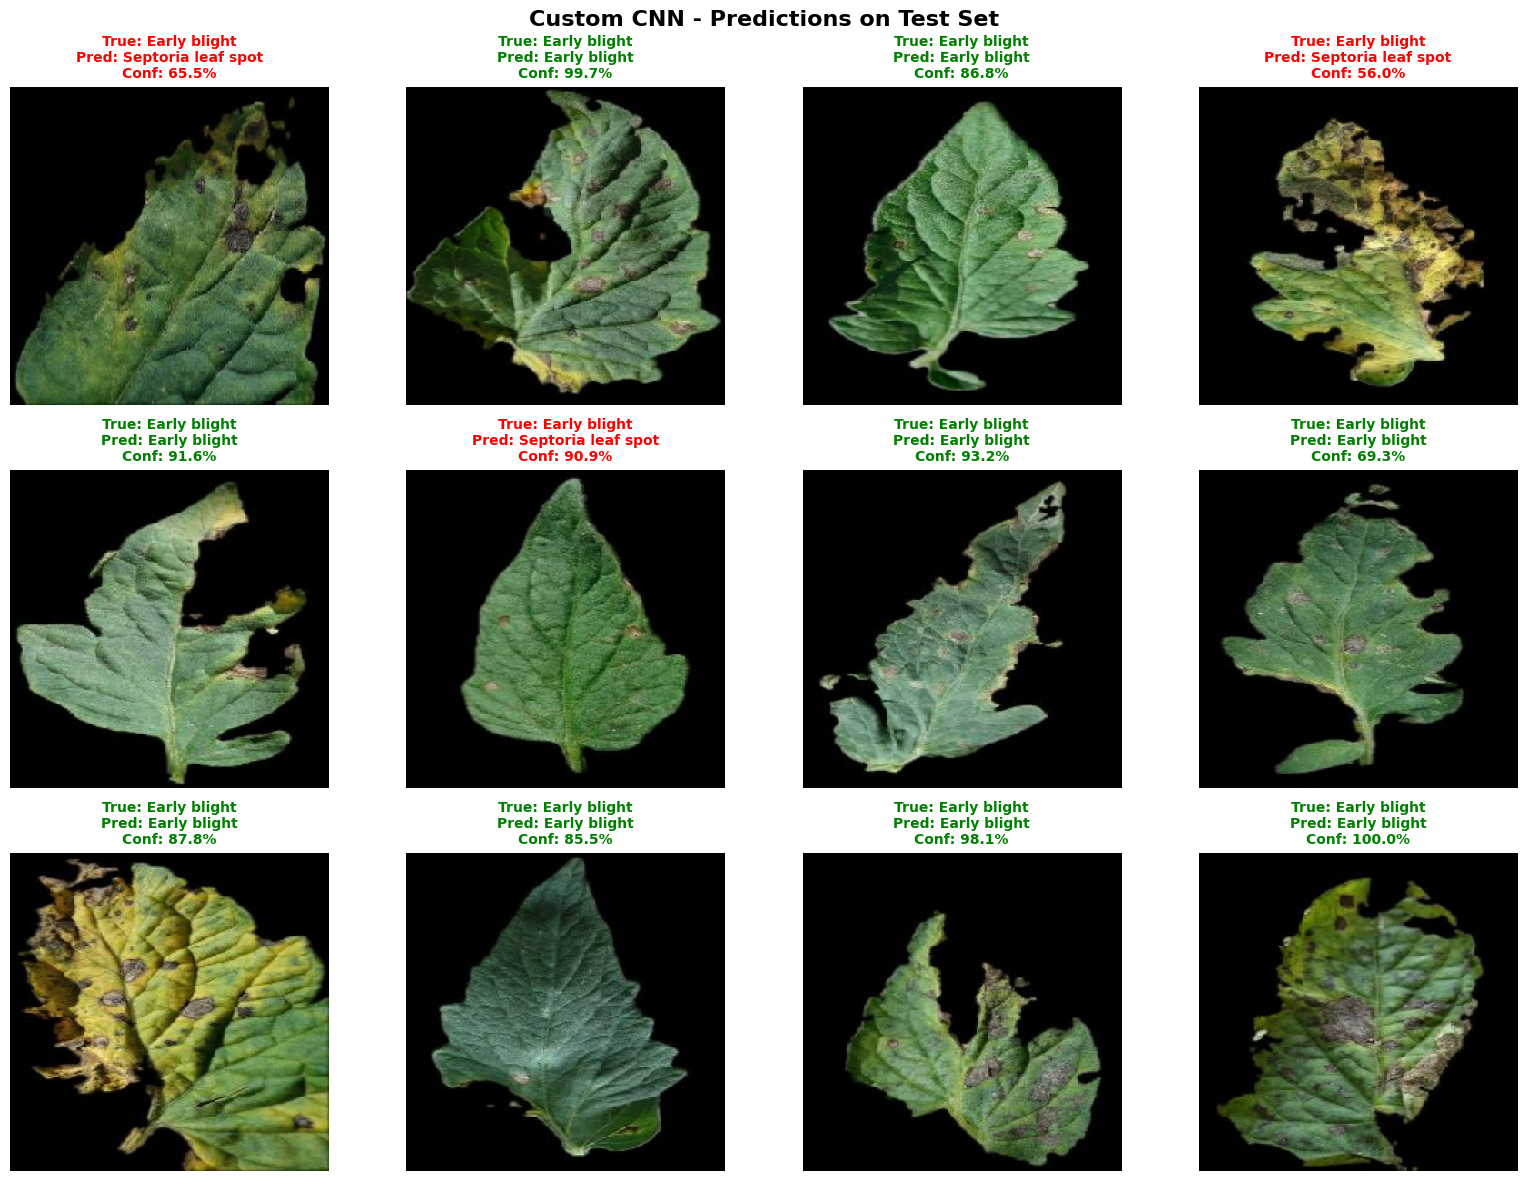

2026-01-12 22:58:09.538692: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


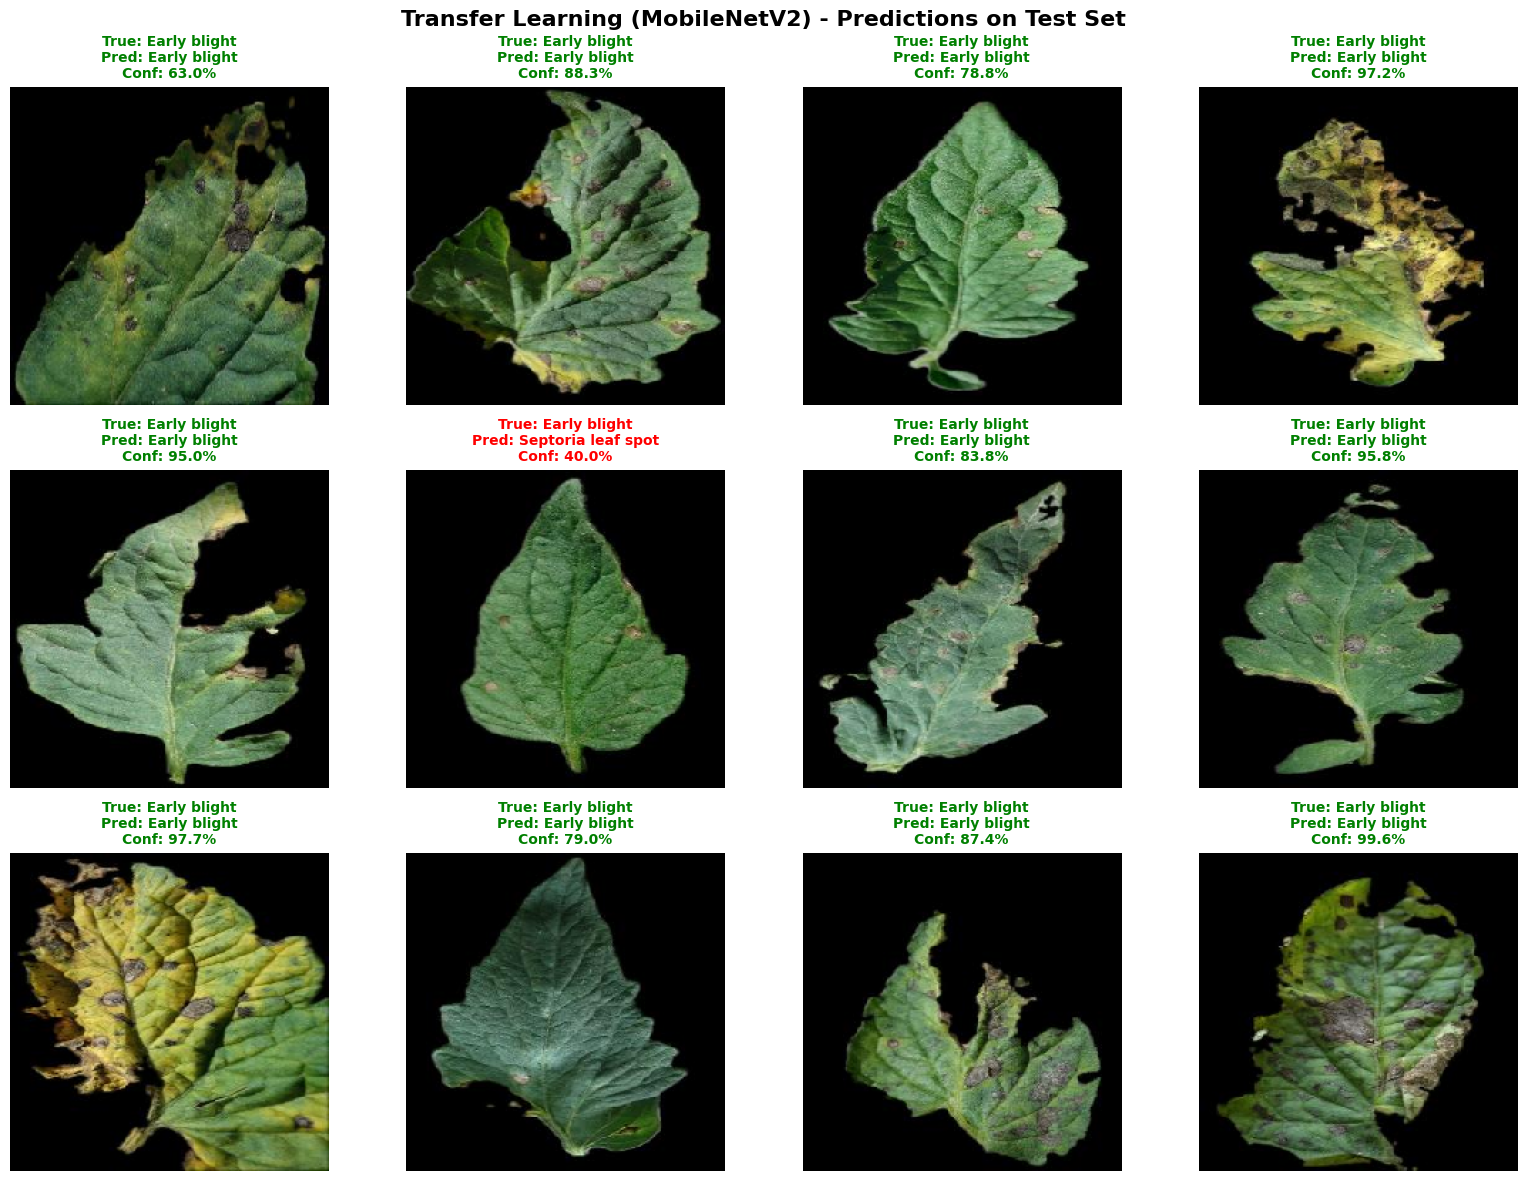

In [11]:
# ============================================================================
# STEP 12: VISUALIZE PREDICTIONS
# ============================================================================

def visualize_predictions(model, test_generator, num_images=12, model_name="Model"):
    """Visualize model predictions"""
    
    # Get predictions
    test_generator.reset()
    images, labels = next(test_generator)
    predictions = model.predict(images, verbose=0)
    
    class_names = list(test_generator.class_indices.keys())
    class_names = [name.replace('Tomato___', '').replace('_', ' ') for name in class_names]
    
    # Create grid
    rows = 3
    cols = 4
    fig, axes = plt.subplots(rows, cols, figsize=(16, 12))
    axes = axes.flatten()
    fig.suptitle(f'{model_name} - Predictions on Test Set', fontsize=16, fontweight='bold')
    
    for i in range(min(num_images, len(images))):
        ax = axes[i]
        
        # Display image
        ax.imshow(images[i])
        
        # Get prediction
        pred_idx = np.argmax(predictions[i])
        true_idx = np.argmax(labels[i])
        confidence = predictions[i][pred_idx] * 100
        
        pred_name = class_names[pred_idx]
        true_name = class_names[true_idx]
        
        # Color code: green if correct, red if wrong
        color = 'green' if pred_idx == true_idx else 'red'
        
        title = f"True: {true_name}\nPred: {pred_name}\nConf: {confidence:.1f}%"
        ax.set_title(title, fontsize=10, fontweight='bold', color=color)
        ax.axis('off')
    
    # Hide extra subplots
    for i in range(num_images, len(axes)):
        axes[i].axis('off')
    
    plt.tight_layout()
    plt.show()


# ============================================================================
# Visualize predictions for all models (uncomment after training)
# ============================================================================

# Custom CNN
visualize_predictions(custom_cnn, test_gen, num_images=12, model_name="Custom CNN")

# MobileNetV2 Transfer Learning
visualize_predictions(mobilenet_model, test_gen, num_images=12, model_name="Transfer Learning (MobileNetV2)")

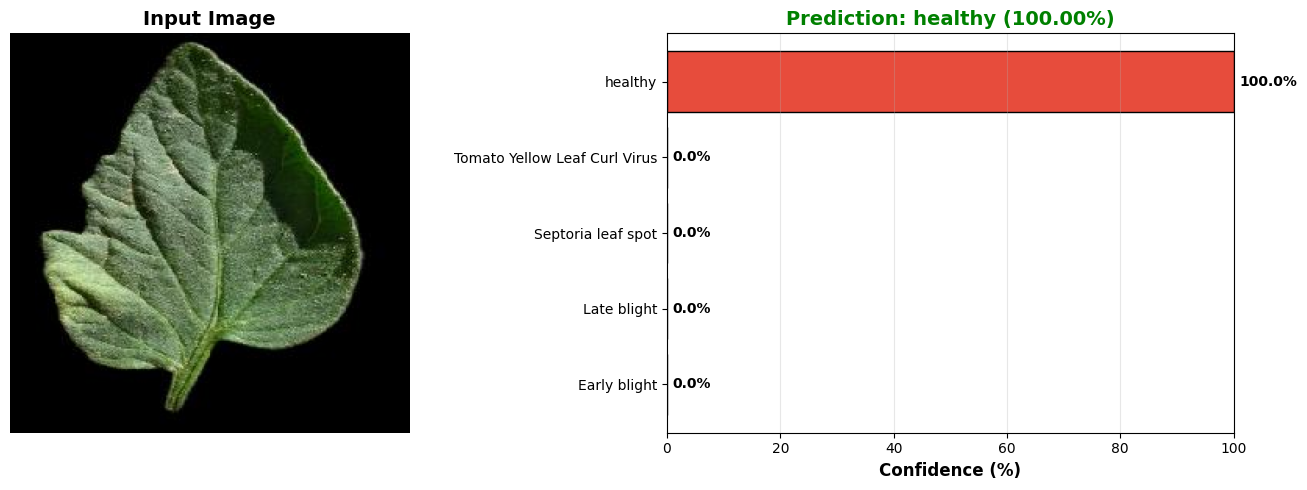


PREDICTION RESULTS
Predicted Class: healthy
Confidence: 100.00%

All Class Probabilities:
Early blight             :   0.00% 
Late blight              :   0.00% 
Septoria leaf spot       :   0.00% 
Tomato Yellow Leaf Curl Virus:   0.00% 
healthy                  : 100.00% ██████████████████████████████████████████████████

[Custom CNN] Predicted: healthy (100.00%)


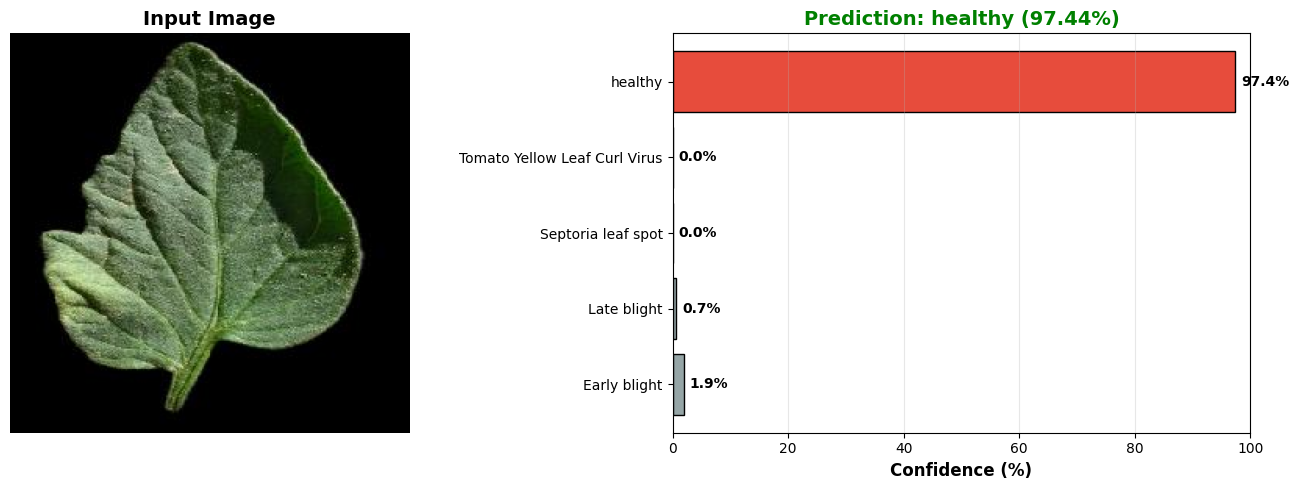


PREDICTION RESULTS
Predicted Class: healthy
Confidence: 97.44%

All Class Probabilities:
Early blight             :   1.92% 
Late blight              :   0.66% 
Septoria leaf spot       :   0.03% 
Tomato Yellow Leaf Curl Virus:   0.00% 
healthy                  :  97.44% ████████████████████████████████████████████████

[MobileNetV2] Predicted: healthy (97.44%)


In [13]:
# ============================================================================
# STEP 14: SIMPLE DEMO - PREDICT SINGLE IMAGE
# ============================================================================

def predict_single_image(model, image_path, test_generator=None, class_names=None):
    """
    Predict disease for a single image
    
    Args:
        model: Trained model
        image_path: Path to image file
        test_generator: Generator to get class names (if class_names not provided)
        class_names: List of class names
    
    Returns:
        predicted_class, confidence
    """
    
    # Get class names from test_generator if not provided
    if class_names is None:
        if test_generator is not None:
            class_names = list(test_generator.class_indices.keys())
            class_names = [name.replace('Tomato___', '').replace('_', ' ') for name in class_names]
        else:
            class_names = ['Early Blight', 'Late Blight', 'Healthy', 'Septoria Leaf Spot', 'Yellow Leaf Curl Virus']
    
    # Load and preprocess image
    img = Image.open(image_path).convert('RGB')
    img_resized = img.resize((IMG_SIZE, IMG_SIZE))
    img_array = np.array(img_resized) / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    
    # Make prediction
    predictions = model.predict(img_array, verbose=0)
    pred_idx = np.argmax(predictions[0])
    confidence = predictions[0][pred_idx] * 100
    
    # Display result
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Show image
    axes[0].imshow(img)
    axes[0].axis('off')
    axes[0].set_title(f"Input Image", fontsize=14, fontweight='bold')
    
    # Show predictions bar chart
    colors = ['#e74c3c' if i == pred_idx else '#95a5a6' for i in range(len(class_names))]
    bars = axes[1].barh(class_names, predictions[0] * 100, color=colors, edgecolor='black')
    axes[1].set_xlabel('Confidence (%)', fontsize=12, fontweight='bold')
    axes[1].set_title(f"Prediction: {class_names[pred_idx]} ({confidence:.2f}%)", 
                     fontsize=14, fontweight='bold',
                     color='green' if confidence > 80 else 'orange')
    axes[1].set_xlim([0, 100])
    axes[1].grid(axis='x', alpha=0.3)
    
    # Add value labels
    for bar in bars:
        width = bar.get_width()
        axes[1].text(width + 1, bar.get_y() + bar.get_height()/2,
                    f'{width:.1f}%', ha='left', va='center', fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
    # Print detailed results
    print(f"\n{'='*70}")
    print(f"PREDICTION RESULTS")
    print(f"{'='*70}")
    print(f"Predicted Class: {class_names[pred_idx]}")
    print(f"Confidence: {confidence:.2f}%")
    print(f"\nAll Class Probabilities:")
    print("="*70)
    for i, class_name in enumerate(class_names):
        prob = predictions[0][i] * 100
        bar = '█' * int(prob / 2)
        print(f"{class_name:<25}: {prob:6.2f}% {bar}")
    
    return class_names[pred_idx], confidence


# ============================================================================
# Example usage
# ============================================================================

image_path = '/mnt/c/Users/Jimmy/anaconda_projects/cv project/plantvillage dataset/segmented/Tomato___healthy/0a0d6a11-ddd6-4dac-8469-d5f65af5afca___RS_HL 0555_final_masked.jpg'

# Predict with Custom CNN
predicted_class_custom, confidence_custom = predict_single_image(custom_cnn, image_path, test_generator=test_gen)
print(f"\n[Custom CNN] Predicted: {predicted_class_custom} ({confidence_custom:.2f}%)")

# Predict with MobileNetV2
predicted_class_mobilenet, confidence_mobilenet = predict_single_image(mobilenet_model, image_path, test_generator=test_gen)
print(f"\n[MobileNetV2] Predicted: {predicted_class_mobilenet} ({confidence_mobilenet:.2f}%)")

In [2]:
# ============================================================================
# STEP 15: SAVE AND LOAD MODELS
# ============================================================================

def save_model_with_info(model, filepath, history=None, test_accuracy=None):
    """Save model with additional information"""
    
    # Save model
    model.save(filepath)
    print(f"✓ Model saved to: {filepath}")
    
    # Save model info
    info = {
        'model_name': model.name,
        'total_params': model.count_params(),
        'input_shape': (IMG_SIZE, IMG_SIZE, 3),
        'num_classes': NUM_CLASSES,
        'class_names': CLASS_NAMES
    }
    
    if test_accuracy is not None:
        info['test_accuracy'] = test_accuracy
    
    if history is not None:
        info['training_epochs'] = len(history.history['accuracy'])
        info['final_train_accuracy'] = float(history.history['accuracy'][-1])
        info['final_val_accuracy'] = float(history.history['val_accuracy'][-1])
    
    # Save info as JSON
    info_path = filepath.replace('.keras', '_info.json')
    with open(info_path, 'w') as f:
        json.dump(info, f, indent=4)
    
    print(f"✓ Model info saved to: {info_path}")


def load_model_for_prediction(filepath):
    """Load a saved model for prediction"""
    
    print(f"Loading model from: {filepath}")
    model = keras.models.load_model(filepath)
    print("✓ Model loaded successfully!")
    
    # Load info if available
    info_path = filepath.replace('.keras', '_info.json')
    if os.path.exists(info_path):
        with open(info_path, 'r') as f:
            info = json.load(f)
        print("\nModel Information:")
        for key, value in info.items():
            print(f"  {key}: {value}")
    
    return model



In [ ]:
# ============================================================================
# Example: Save models with info 
# ============================================================================

# Save Custom CNN
save_model_with_info(
    custom_cnn,
    'models/custom_cnn_best.keras',
    history=history_custom,
    test_accuracy=custom_acc
)


# Save MobileNetV2 Transfer Learning
save_model_with_info(
    mobilenet_model,
    'models/mobilenetv2_best.keras',
    history=history_mobilenet_phase1,
    test_accuracy=mobilenet_acc
)

In [3]:
# ============================================================================
# Example: Load models for prediction
# ============================================================================
custom_cnn = load_model_for_prediction('models/custom_cnn_best.keras')
mobilenet_model = load_model_for_prediction('models/mobilenetv2_best.keras')

Loading model from: models/custom_cnn_best.keras


I0000 00:00:1768487169.732693   23828 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3537 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9
/home/jimmy_linux/venvs/ml_env/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 42 variables whereas the saved optimizer has 78 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/home/jimmy_linux/venvs/ml_env/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 38 variables whereas the saved optimizer has 74 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


✓ Model loaded successfully!

Model Information:
  model_name: Custom_CNN
  total_params: 26410277
  input_shape: [224, 224, 3]
  num_classes: 5
  class_names: ['Tomato___healthy', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Septoria_leaf_spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus']
  test_accuracy: 0.892
  training_epochs: 60
  final_train_accuracy: 0.9617142677307129
  final_val_accuracy: 0.9173333048820496
Loading model from: models/mobilenetv2_best.keras
✓ Model loaded successfully!

Model Information:
  model_name: Transfer_Learning_MobileNetV2
  total_params: 2625605
  input_shape: [224, 224, 3]
  num_classes: 5
  class_names: ['Tomato___healthy', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Septoria_leaf_spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus']
  test_accuracy: 0.9453333333333334
  training_epochs: 60
  final_train_accuracy: 0.9194285869598389
  final_val_accuracy: 0.9333333373069763


/home/jimmy_linux/venvs/ml_env/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 16 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/home/jimmy_linux/venvs/ml_env/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 12 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [4]:
# ============================================================================
# STEP 16: CREATE INTERACTIVE DEMO
# ============================================================================

import gradio as gr

print("\n" + "="*70)
print("STEP 16: INTERACTIVE DEMO SETUP")
print("="*70)

# Define class names for the demo
CLASS_NAMES = ['Tomato___healthy', 'Tomato___Early_blight', 'Tomato___Late_blight', 
               'Tomato___Septoria_leaf_spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus']

def predict_with_model(image, model_choice):
    """Compare predictions from both models"""
    img = Image.fromarray(image).convert('RGB')
    img_resized = img.resize((224, 224))
    img_array = np.array(img_resized) / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    
    # Select model
    model = custom_cnn if model_choice == "Custom CNN" else mobilenet_model
    predictions = model.predict(img_array, verbose=0)
    
    class_names = [name.replace('Tomato___', '').replace('_', ' ') 
                   for name in CLASS_NAMES]
    results = {class_names[i]: float(predictions[0][i]) 
               for i in range(len(class_names))}
    
    return results

# Build interface with tabs
with gr.Blocks(title="Plant Disease Detection") as demo:
    gr.Markdown("# 🌿 Tomato Disease Detection System")
    
    with gr.Tabs():
        with gr.TabItem("Single Prediction"):
            with gr.Row():
                image_input = gr.Image(type="numpy", label="Upload Image")
                model_choice = gr.Radio(
                    ["Custom CNN", "MobileNetV2"],
                    value="MobileNetV2",
                    label="Select Model"
                )
            
            output = gr.Label(num_top_classes=5)
            predict_btn = gr.Button("Predict", variant="primary")
            predict_btn.click(predict_with_model, 
                            inputs=[image_input, model_choice], 
                            outputs=output)
        
        with gr.TabItem("Compare Models"):
            gr.Markdown("Compare predictions from both models side-by-side")
            image_input2 = gr.Image(type="numpy", label="Upload Image")
            
            with gr.Row():
                output_cnn = gr.Label(label="Custom CNN")
                output_mobile = gr.Label(label="MobileNetV2")
            
            compare_btn = gr.Button("Compare", variant="primary")
            compare_btn.click(
                lambda img: (
                    predict_with_model(img, "Custom CNN"),
                    predict_with_model(img, "MobileNetV2")
                ),
                inputs=image_input2,
                outputs=[output_cnn, output_mobile]
            )

demo.launch(share=True)


STEP 16: INTERACTIVE DEMO SETUP
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://b3a70aeb732b011e9b.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


ERROR:    Exception in ASGI application
Traceback (most recent call last):
  File "/home/jimmy_linux/venvs/ml_env/lib/python3.12/site-packages/uvicorn/protocols/http/h11_impl.py", line 410, in run_asgi
    result = await app(  # type: ignore[func-returns-value]
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/jimmy_linux/venvs/ml_env/lib/python3.12/site-packages/uvicorn/middleware/proxy_headers.py", line 60, in __call__
    return await self.app(scope, receive, send)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/jimmy_linux/venvs/ml_env/lib/python3.12/site-packages/fastapi/applications.py", line 1135, in __call__
    await super().__call__(scope, receive, send)
  File "/home/jimmy_linux/venvs/ml_env/lib/python3.12/site-packages/starlette/applications.py", line 107, in __call__
    await self.middleware_stack(scope, receive, send)
  File "/home/jimmy_linux/venvs/ml_env/lib/python3.12/site-packages/starlette/middleware/errors.py", line 186, in __c